<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-09/lab-049-reservoir-climate.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 049 <br>
<hr/>

# Lab 049 — Weather and climate of an echo state network

An echo state network (ESN) is a fixed random recurrent network driven by a signal, with a linear readout fitted by ridge regression [H. Jaeger, H. Haas, Science **304**, 78 (2004), [doi:10.1126/science.1091277](https://doi.org/10.1126/science.1091277)]. We train it one step ahead on the full state of the Lorenz-63 system and then close the loop. The prediction of the readout becomes the next input, and the trained reservoir turns into an autonomous dynamical system with no data coming in. Pathak, Lu, Hunt, Girvan and Ott showed that such a closed-loop reservoir can reproduce a chaotic attractor and its Lyapunov exponents [Chaos **27**, 121102 (2017), [doi:10.1063/1.5010300](https://doi.org/10.1063/1.5010300)], and Lu, Hunt and Ott studied when this reconstruction succeeds [Chaos **28**, 061104 (2018), [doi:10.1063/1.5039508](https://doi.org/10.1063/1.5039508)].

The closed-loop model is judged on two time scales. The short-term forecast of one trajectory is commonly called the weather of the model, and it is limited by chaos to a few Lyapunov times. The long-term statistics of the free run are commonly called its climate. They include the invariant densities, the return map of the maxima of $z$, the power spectrum and the Lyapunov exponents, and they can be right long after the individual trajectory is lost.

We first describe the Lorenz-63 system and compute its Lyapunov exponents with the tangent-vector method of Benettin and co-workers. We then train one ESN, measure the valid time of its forecasts from 190 origins and compare it with the predictability time set by the largest exponent. A free run of about 1988 Lyapunov times gives the climate, including the Lyapunov exponents of the reservoir map, computed with JAX Jacobians. Over 240 random reservoirs we count how often the free run stays on a Lorenz-like attractor and how often it ends on a fixed point, on a periodic orbit or diverges. Linear and quadratic autoregression in closed loop and a reservoir that sees only the coordinate $x$ complete the picture.

The implementation uses JAX in double precision. Every trajectory and every free run is one `jax.lax.scan` over time.

> **Running this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> and choose *File, Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`. The recorded run of the whole notebook took 10 minutes on a multi-core CPU that was shared with other jobs.
> 2. `jax`, `scipy` and `matplotlib` are pre-installed in Colab. No data file is needed.
> 3. Run the cells in order. Later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
from functools import partial
from collections import Counter
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse, FancyArrowPatch

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # all computations of this notebook in float64
import scipy
from scipy.stats import wasserstein_distance
from scipy.signal import welch

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
# one colour per class of free run, used in every figure
CLASSES = ("Lorenz-like", "aperiodic, wrong climate", "periodic", "fixed point", "diverged")
CCOL = {"Lorenz-like": UJBlue, "aperiodic, wrong climate": "#2A9D8F", "periodic": DSOrange,
        "fixed point": UJGray, "diverged": "#C44E52"}

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

nums = {}                 # every number a slide may need, written to the numbers file at the end
t_start = time.time()
print("jax", jax.__version__, "| scipy", scipy.__version__)

jax 0.11.0 | scipy 1.15.3


<hr/>
## 1. Lorenz-63 system

Lorenz derived three ordinary differential equations from a truncated model of thermal convection in a fluid layer heated from below [E. N. Lorenz, J. Atmos. Sci. **20**, 130 (1963), [doi:10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2](https://doi.org/10.1175/1520-0469(1963)020%3C0130:DNF%3E2.0.CO;2)]. The variable $x$ is proportional to the intensity of the convective motion, $y$ to the temperature difference between the rising and the sinking fluid, and $z$ to the deviation of the vertical temperature profile from a linear one,
$$\dot x=10\,(y-x),\qquad \dot y=x\,(28-z)-y,\qquad \dot z=xy-\tfrac83\, z ,$$
with the parameter values of Lorenz's paper. The equations are unchanged under $(x,y,z)\to(-x,-y,z)$, which exchanges the two senses of rotation of the convection roll. The state of rest is unstable, and two fixed points
$$C_\pm=\Big(\pm\sqrt{\tfrac83\cdot27},\ \pm\sqrt{\tfrac83\cdot27},\ 27\Big)=(\pm8.485,\ \pm8.485,\ 27)$$
describe steady convection in either sense. When the coefficient 28 in the second equation is raised from small values, these fixed points lose their stability at 24.74, so at 28 they are unstable. The trajectory spirals around one of them, jumps irregularly to the other and never settles. The phase volume contracts at the constant rate $\nabla\cdot\dot{\mathbf u}=-(10+1+\tfrac83)=-\tfrac{41}{3}$, so the motion lives on a set of zero volume, the strange attractor.

We integrate the equations with the fourth-order Runge–Kutta method (RK4) at step $h=0.01$ and keep every second point, so the sampling interval is $\Delta t=0.02$. After a transient of 50 time units we generate a training block of 10000 samples, a test block of 20000 samples and a long block of 110000 samples for the climate comparison. A second long run from an independent initial state measures how much two true runs of this length differ. The figure shows the projection of 50 time units on the $(x,z)$ plane with $C_\pm$ (orange) and the coordinate $x(t)$ over 30 time units, with the dotted lines at $x=\pm8.49$.

r_H = 24.737
fixed points C+- = (+-8.485, +-8.485, 27); samples train 10000, test 20000, long 110000


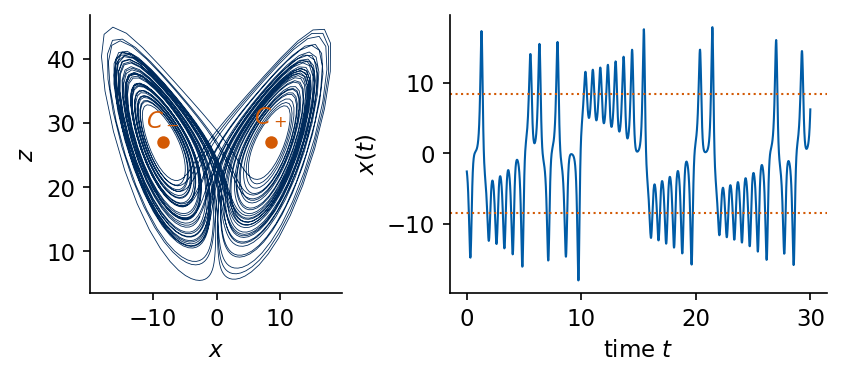

In [2]:
# Lorenz-63 with the parameter values 10, 28 and 8/3 of Lorenz's paper
SIG_L, R_L, B_L = 10.0, 28.0, 8.0 / 3.0
def lorenz_rhs(u):
    # dx/dt = 10 (y - x), dy/dt = x (28 - z) - y, dz/dt = x y - 8/3 z
    x, y, z = u
    return jnp.array([SIG_L * (y - x), x * (R_L - z) - y, x * y - B_L * z])

def rk4_step(f, u, h):
    k1 = f(u); k2 = f(u + 0.5 * h * k1); k3 = f(u + 0.5 * h * k2); k4 = f(u + h * k3)
    return u + h / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)

H_RK, SUB = 0.01, 2                 # RK4 step h = 0.01, one sample every 2 steps
DT = H_RK * SUB                     # sampling interval Delta t = 0.02
def flow(u):
    # the sampled flow map u(t) -> u(t + Delta t)
    return jax.lax.fori_loop(0, SUB, lambda i, v: rk4_step(lorenz_rhs, v, H_RK), u)

@partial(jax.jit, static_argnums=(1,))
def trajectory(u0, n):
    # n samples u(Delta t), ..., u(n Delta t) after u0
    def one(u, _):
        u = flow(u)
        return u, u
    return jax.lax.scan(one, u0, None, length=n)[1]

N_TRAIN, N_TEST, N_LONG = 10000, 20000, 110000
u_on = trajectory(jnp.array([1.0, 1.0, 1.0]), 2500)[-1]          # 50 time units of transient discarded
U_phys = np.asarray(trajectory(u_on, N_TRAIN + 1 + N_TEST + N_LONG))
U_long_p = U_phys[N_TRAIN + 1 + N_TEST:]                            # truth for the climate comparison
u_on2 = trajectory(jnp.array([-3.0, 2.0, 30.0]), 2500)[-1]         # a second, independent long run
U_long2_p = np.asarray(trajectory(u_on2, N_LONG))

x_c = np.sqrt(B_L * (R_L - 1.0))                                    # fixed points C+-: (+-x_c, +-x_c, 27), x_c = sqrt(8/3 * 27)
r_H = SIG_L * (SIG_L + B_L + 3) / (SIG_L - B_L - 1)                 # C+- lose stability when the coefficient 28 exceeds r_H
nums["lorenz"] = dict(dt=DT, n_train=N_TRAIN, n_test=N_TEST, n_long=N_LONG, x_c=float(x_c), z_c=R_L - 1, r_H=r_H)
print(f"r_H = {r_H:.3f}")
print(f"fixed points C+- = (+-{x_c:.3f}, +-{x_c:.3f}, {R_L - 1:.0f}); samples train {N_TRAIN}, test {N_TEST}, long {N_LONG}")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained", width_ratios=(1, 1.5))
    seg = U_phys[:2500]                                              # 50 time units
    axs[0].plot(seg[:, 0], seg[:, 2], color=UJNavy, lw=0.4)
    axs[0].plot([x_c, -x_c], [R_L - 1, R_L - 1], "o", color=DSOrange, ms=5)
    axs[0].text(x_c, R_L + 1, r"$C_+$", color=DSOrange, va="bottom", ha="center")
    axs[0].text(-x_c, R_L + 1, r"$C_-$", color=DSOrange, va="bottom", ha="center")
    axs[0].set_xlabel("$x$"); axs[0].set_ylabel("$z$")
    t = np.arange(1, 1501) * DT
    axs[1].plot(t, U_phys[:1500, 0], color=UJBlue, lw=1.0)
    axs[1].axhline(x_c, color=DSOrange, ls=":", lw=1.0); axs[1].axhline(-x_c, color=DSOrange, ls=":", lw=1.0)
    axs[1].set_xlabel("time $t$"); axs[1].set_ylabel("$x(t)$")
    save(fig, "fig_lab049_lorenz"); plt.show()

<hr/>
## 2. Lyapunov exponents and predictability

Two trajectories that start a small distance $\delta_0$ apart separate on average as $\delta(t)\approx\delta_0 e^{\lambda_1 t}$, where $\lambda_1$ is the largest Lyapunov exponent. The full set $\lambda_1\ge\lambda_2\ge\lambda_3$ describes the growth of lengths, areas and volumes in the tangent space. Benettin, Galgani, Giorgilli and Strelcyn computed them by pushing a set of tangent vectors with the Jacobian of the flow and orthonormalising them regularly [Meccanica **15**, 9 (1980), [doi:10.1007/BF02128236](https://doi.org/10.1007/BF02128236); Meccanica **15**, 21 (1980), [doi:10.1007/BF02128237](https://doi.org/10.1007/BF02128237)]. With the flow map $\mathbf u_{k+1}=\Phi(\mathbf u_k)$ over one sampling interval and its Jacobian $D\Phi(\mathbf u_k)$, every step reads
$$D\Phi(\mathbf u_k)\,Q_k=Q_{k+1}R_{k+1},\qquad \lambda_i=\frac{1}{n\,\Delta t}\sum_{k=1}^{n}\ln\big|(R_k)_{ii}\big| ,$$
where $Q_k$ has orthonormal columns and $R_k$ is upper triangular (QR decomposition). JAX gives the product $D\Phi\,\mathbf q$ of the Jacobian with a tangent vector directly through `jax.jvp`, differentiated through the RK4 steps, so the Jacobian matrix is never formed.

The run covers 3980 time units. The left panel shows the running averages of $\lambda_1$ and $\lambda_2$ and the right panel that of $\lambda_3$. The estimates are
$$\lambda_1=0.904\pm0.002,\qquad \lambda_2=-0.0001\pm0.0010,\qquad \lambda_3=-14.57\pm0.002,$$
with the standard error from ten blocks. The second exponent belongs to the direction along the flow and vanishes for every bounded trajectory that does not end on a fixed point, which the estimate confirms within its error. The sum of the three exponents is $-13.6666$, equal to the contraction rate $-41/3=-13.6667$ to the fourth digit.

The Lyapunov time $T_\lambda=1/\lambda_1=1.11$ time units, or 55 samples, sets the time scale of the weather. An error of initial size $\delta_0$ reaches a tolerance $\varepsilon$ after the predictability time
$$T_p=\frac{1}{\lambda_1}\ln\frac{\varepsilon}{\delta_0},$$
which grows only logarithmically with the precision of the initial state. In these units the training block covers 181 Lyapunov times and the long block 1988.

lambda_1 = +0.9036 +- 0.0024
lambda_2 = -0.0001 +- 0.0010
lambda_3 = -14.5701 +- 0.0023
sum = -13.6666, -(10 + 1 + 8/3) = -41/3 = -13.6667; Lyapunov time 1/lambda_1 = 1.107 = 55.3 samples (1.4 s)


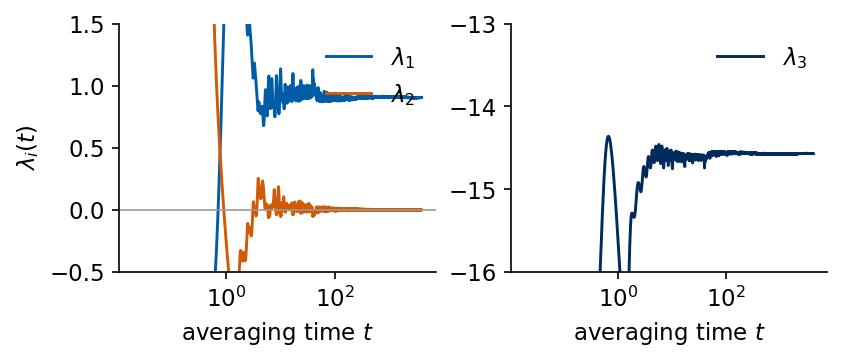

In [3]:
@partial(jax.jit, static_argnums=(0, 4))
def benettin(step, x0, Q0, params, n):
    # Benettin method: tangent vectors Q (columns) pushed by the Jacobian of `step` (jax.jvp),
    # re-orthonormalised by a QR decomposition; returns log|R_ii| of every step, shape (n, k)
    def body(carry, _):
        x, Q = carry
        x_new, JQ = jax.vmap(lambda q: jax.jvp(lambda v: step(v, params), (x,), (q,)),
                             in_axes=1, out_axes=(None, 1))(Q)
        Q, R = jnp.linalg.qr(JQ)
        return (x_new, Q), jnp.log(jnp.abs(jnp.diag(R)))
    _, logs = jax.lax.scan(body, (x0, Q0), None, length=n)
    return logs

def lorenz_step(u, params):
    return flow(u)

N_LE, N_LE_SKIP = 200000, 1000                    # 4000 time units, the first 20 discarded
t0 = time.time()
logs = np.asarray(benettin(lorenz_step, u_on, jnp.eye(3), None, N_LE))[N_LE_SKIP:]
lam_true = logs.mean(0) / DT
blocks = logs.reshape(10, -1, 3).mean(1) / DT     # ten blocks of 398 time units
lam_err = blocks.std(0, ddof=1) / np.sqrt(10)
lam1 = float(lam_true[0])
T_LYAP = 1.0 / lam1                               # Lyapunov time
nums["lyap_true"] = dict(lam=lam_true.tolist(), err=lam_err.tolist(), sum=float(lam_true.sum()),
                         trace=-(SIG_L + 1 + B_L), T_lyap=T_LYAP, steps_per_T=T_LYAP / DT,
                         long_in_T=N_LONG * DT / T_LYAP, train_in_T=N_TRAIN * DT / T_LYAP,
                         time_units=(N_LE - N_LE_SKIP) * DT)
for i in range(3):
    print(f"lambda_{i+1} = {lam_true[i]:+.4f} +- {lam_err[i]:.4f}")
print(f"sum = {lam_true.sum():.4f}, -(10 + 1 + 8/3) = -41/3 = {-(SIG_L + 1 + B_L):.4f}; Lyapunov time 1/lambda_1 = {T_LYAP:.3f}"
      f" = {T_LYAP / DT:.1f} samples ({time.time() - t0:.1f} s)")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained")
    tt = (np.arange(1, len(logs) + 1)) * DT
    run = np.cumsum(logs, 0) / np.arange(1, len(logs) + 1)[:, None] / DT
    axs[0].semilogx(tt, run[:, 0], color=UJBlue, label=r"$\lambda_1$")
    axs[0].semilogx(tt, run[:, 1], color=DSOrange, label=r"$\lambda_2$")
    axs[0].axhline(0, color="0.6", lw=0.8); axs[0].set_ylim(-0.5, 1.5)
    axs[0].set_xlabel("averaging time $t$"); axs[0].set_ylabel(r"$\lambda_i(t)$"); axs[0].legend(loc="upper right")
    axs[1].semilogx(tt, run[:, 2], color=UJNavy, label=r"$\lambda_3$")
    axs[1].set_ylim(-16, -13); axs[1].set_xlabel("averaging time $t$"); axs[1].legend(loc="upper right")
    save(fig, "fig_lab049_lyap_lorenz"); plt.show()

<hr/>
## 3. Echo state network in open and closed loop

The three coordinates are normalised by the mean and standard deviation of the training block, and $\mathbf u_k\in\mathbb R^3$ denotes the normalised state at time $k\Delta t$. For a scalar record $s_k$ the leaky ESN updates its state $\mathbf r_k\in\mathbb R^N$ by
$$\mathbf r_k=(1-\alpha)\,\mathbf r_{k-1}+\alpha\tanh\big(W\mathbf r_{k-1}+\mathbf w_{\rm in}s_k\big),$$
with the leak rate $\alpha$. Here the input is the three-component state, so the input weights become an $N\times3$ matrix $W_{\rm in}$ with one column $\mathbf w_{\rm in}$ per coordinate, and every unit gets a fixed bias $\theta_i$. In the open loop the reservoir is driven by the data,
$$\mathbf r_k=(1-\alpha)\,\mathbf r_{k-1}+\alpha\tanh\big(W\mathbf r_{k-1}+W_{\rm in}\mathbf u_k+\boldsymbol\theta\big),\qquad \hat{\mathbf u}_{k+1}=W_{\rm out}^\top\mathbf r_k+\mathbf b .$$
We use $\alpha=1$ throughout. The recurrent matrix $W$ is a sparse random $N\times N$ matrix with 5% nonzero Gaussian entries, rescaled to the spectral radius $\rho$, the largest modulus of its eigenvalues. The entries of $W_{\rm in}$ are uniform in $[-\sigma_{\rm in},\sigma_{\rm in}]$ and those of $\boldsymbol\theta$ uniform in $[-0.1,0.1]$. Only the readout weights $W_{\rm out}$ and the offset $\mathbf b$ are trained, by ridge regression with strength $\beta$, a least-squares fit with the added penalty $\beta\|W_{\rm out}\|^2$, on the one-step targets $\mathbf u_{k+1}$ of the training block. The reservoir starts from $\mathbf r_0=0$, and the first 200 states, the washout, are left out of the fit because they still remember this arbitrary start. The washout and the synchronised start of the forecasts below rely on the echo state property, which states that two copies of the reservoir started in different states and driven by the same input converge to the same state, so that after a transient the state depends on the input history alone. Without the bias the update is odd under the joint sign change $(\mathbf r,\mathbf u)\to(-\mathbf r,-\mathbf u)$, a symmetry that the Lorenz flow lacks, since $z\to-z$ changes the equations.

In the closed loop the prediction replaces the data,
$$\mathbf r_{k+1}=(1-\alpha)\,\mathbf r_k+\alpha\tanh\big(W\mathbf r_k+W_{\rm in}(W_{\rm out}^\top\mathbf r_k+\mathbf b)+\boldsymbol\theta\big)\ \eqqcolon\ F(\mathbf r_k).$$
The map $F$ is an autonomous dynamical system on $\mathbb R^N$ with no external input. A forecast starts from the state $\mathbf r_k$ reached by driving the reservoir with the true record up to time $k$, and a free run continues $F$ for as long as we like. The drawing shows the two modes. The input weights (dashed blue) and couplings (grey) are random and fixed, the readout (orange) is trained in the open loop, and in the closed loop its output is fed back as the next input.

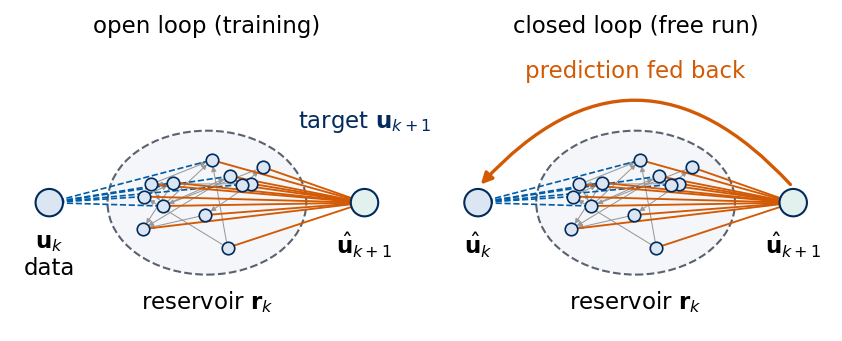

In [4]:
def draw_reservoir(ax, cx, closed):
    rng = np.random.default_rng(3)
    n_res = 12
    ang = rng.uniform(0, 2 * np.pi, n_res); rad = np.sqrt(rng.uniform(0.05, 1, n_res))
    P = np.c_[cx + 1.1 * rad * np.cos(ang), 1.2 + 0.8 * rad * np.sin(ang)]
    ax.add_patch(Ellipse((cx, 1.2), 2.9, 2.1, fc="#F4F6F9", ec=UJGray, ls="--", lw=1.0, zorder=0))
    for i in range(n_res):                                # fixed random couplings W
        for j in range(n_res):
            if i != j and rng.random() < 0.15:
                ax.annotate("", xy=P[j], xytext=P[i], arrowprops=dict(arrowstyle="-|>", color="0.6", lw=0.5,
                            shrinkA=3, shrinkB=3, mutation_scale=5), zorder=1)
    s_xy, y_xy = np.array([cx - 2.3, 1.2]), np.array([cx + 2.3, 1.2])
    for i in rng.choice(n_res, 6, replace=False):         # fixed input weights W_in
        ax.plot(*np.c_[s_xy, P[i]], color=UJBlue, lw=0.8, ls="--", zorder=1)
    for i in range(n_res):                                # trained readout W_out
        ax.plot(*np.c_[P[i], y_xy], color=DSOrange, lw=0.9, zorder=1)
    ax.scatter(*P.T, s=36, color="#DCE6F2", edgecolor=UJNavy, lw=0.8, zorder=3)
    ax.add_patch(Circle(s_xy, 0.2, fc="#DCE6F2", ec=UJNavy, zorder=3))
    ax.add_patch(Circle(y_xy, 0.2, fc="#E3F1EE", ec=UJNavy, zorder=3))
    ax.text(cx, -0.05, r"reservoir $\mathbf{r}_k$", ha="center", va="top")
    ax.text(y_xy[0], 0.8, r"$\hat{\mathbf{u}}_{k+1}$", ha="center", va="top")
    if closed:
        ax.text(s_xy[0], 0.8, r"$\hat{\mathbf{u}}_{k}$", ha="center", va="top")
        ax.add_patch(FancyArrowPatch(y_xy + [0, 0.22], s_xy + [0, 0.22], connectionstyle="arc3,rad=0.55",
                                     arrowstyle="-|>", mutation_scale=11, color=DSOrange, lw=1.6, zorder=2))
        ax.text(cx, 2.95, "prediction fed back", color=DSOrange, ha="center", va="bottom")
    else:
        ax.text(s_xy[0], 0.8, r"$\mathbf{u}_{k}$" + "\ndata", ha="center", va="top")
        ax.text(y_xy[0], 2.2, r"target $\mathbf{u}_{k+1}$", ha="center", va="bottom", color=UJNavy)

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained")
    for ax, closed, title in ((axs[0], False, "open loop (training)"), (axs[1], True, "closed loop (free run)")):
        draw_reservoir(ax, 0.0, closed)
        ax.set_title(title, fontsize=11)
        ax.set_xlim(-2.8, 2.8); ax.set_ylim(-0.6, 3.5); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab049_loops"); plt.show()

In [5]:
mu, sd = U_phys[:N_TRAIN].mean(0), U_phys[:N_TRAIN].std(0)     # normalisation from the training block
Un = (U_phys[:N_TRAIN + 1 + N_TEST] - mu) / sd                   # training and test blocks, normalised
Un_long, Un_long2 = (U_long_p - mu) / sd, (U_long2_p - mu) / sd
D_NORM = np.sqrt(Un[:N_TRAIN].var(0).sum())                      # sqrt(<|u - <u>|^2>) = sqrt(3)

ALPHA = 1.0                                                         # leak rate used throughout
def esn_draw(N, seed, rho, sigma_in, sigma_theta, dim=3, density=0.05):
    # sparse Gaussian W rescaled to spectral radius rho, W_in uniform in [-sigma_in, sigma_in], bias uniform in [-sigma_theta, sigma_theta]
    rng = np.random.default_rng(seed)
    W = rng.normal(size=(N, N)) * (rng.random((N, N)) < density)
    W *= rho / np.max(np.abs(np.linalg.eigvals(W)))
    W_in = rng.uniform(-sigma_in, sigma_in, (N, dim))
    theta = rng.uniform(-sigma_theta, sigma_theta, N)
    return dict(W=jnp.asarray(W), W_in=jnp.asarray(W_in), theta=jnp.asarray(theta), alpha=ALPHA)

@jax.jit
def esn_states(p, u, r0):
    # open loop: r_k = (1 - alpha) r_{k-1} + alpha tanh(W r_{k-1} + W_in u_k + theta), returns all states (T, N)
    def step(r, uk):
        r = (1 - p["alpha"]) * r + p["alpha"] * jnp.tanh(p["W"] @ r + p["W_in"] @ uk + p["theta"])
        return r, r
    return jax.lax.scan(step, r0, u)[1]

def ridge_fit(F, Y, beta):
    # centred ridge regression, F: (n, d) features, Y: (n, m) targets -> W (d, m), offset b (m,)
    fm, ym = F.mean(0), Y.mean(0)
    Fc = F - fm
    W = jnp.linalg.solve(Fc.T @ Fc + beta * jnp.eye(F.shape[1]), Fc.T @ (Y - ym))
    return W, ym - fm @ W

N_WASH = 200
def train_esn(p, U, beta):
    # drive with the training and test blocks, fit u_{k+1} = W_out^T r_k + b on k = 200..N_TRAIN-1
    R = esn_states(p, jnp.asarray(U), jnp.zeros(p["W"].shape[0]))
    k = np.arange(N_WASH, N_TRAIN)
    W_out, b = ridge_fit(R[k], jnp.asarray(U[k + 1]), beta)
    pred = np.asarray(R[k] @ W_out + b)
    nmse_one = float(np.mean(np.mean((pred - U[k + 1]) ** 2, 0) / U[k + 1].var(0)))
    return dict(p, W_out=W_out, b=b), R, nmse_one

def closed_step(r, p):
    # closed loop: the prediction u_hat = W_out^T r + b is the next input
    u_hat = r @ p["W_out"] + p["b"]
    return (1 - p["alpha"]) * r + p["alpha"] * jnp.tanh(p["W"] @ r + p["W_in"] @ u_hat + p["theta"])

@partial(jax.jit, static_argnums=(2,))
def free_run_full(r0, p, n):
    # n closed-loop steps from the state r_k; returns the last state and u_hat_{k+1}, ..., u_hat_{k+n}
    def step(r, _):
        return closed_step(r, p), r @ p["W_out"] + p["b"]
    return jax.lax.scan(step, r0, None, length=n)

def free_run(r0, p, n):
    return free_run_full(r0, p, n)[1]

BASE = dict(N=300, rho=0.9, sigma_in=0.1, sigma_theta=0.1, beta=1e-8)
p0 = esn_draw(BASE["N"], 0, BASE["rho"], BASE["sigma_in"], BASE["sigma_theta"])
t0 = time.time()
esn, R_all, nmse_one = train_esn(p0, Un, BASE["beta"])
t_train = time.time() - t0
k_te = np.arange(N_TRAIN, N_TRAIN + N_TEST - 1)
nmse_one_test = float(np.mean(np.mean((np.asarray(R_all[k_te] @ esn["W_out"] + esn["b"]) - Un[k_te + 1]) ** 2, 0)
                              / Un[k_te + 1].var(0)))
nums["esn"] = dict(BASE, n_wash=N_WASH, nmse_one_train=nmse_one, nmse_one_test=nmse_one_test,
                   n_readout=int(esn["W_out"].size + esn["b"].size), t_train=t_train,
                   nonzero=float(np.mean(np.asarray(p0["W"]) != 0)))
print(f"ESN N = {BASE['N']}: one-step NMSE training {nmse_one:.1e}, test {nmse_one_test:.1e};"
      f" {esn['W_out'].size + esn['b'].size} trained numbers; training {t_train:.1f} s")

ESN N = 300: one-step NMSE training 6.5e-12, test 5.7e-11; 903 trained numbers; training 1.7 s


The reservoir used in the next three sections has $N=300$ units, $\rho=0.9$, $\sigma_{\rm in}=0.1$ and $\beta=10^{-8}$, a setting fixed by a short trial before the analysis. The record of that trial is not part of this notebook, and further below, once the classification of free runs is defined, we repeat the choice on the training block alone. Its readout has 903 trained numbers, and the training run plus the ridge solve take 2.6 s. The one-step normalised mean-square error (NMSE), the mean over the three coordinates of the squared error divided by the variance, is $6.5\times10^{-12}$ on the training block and $5.7\times10^{-11}$ on the test block. One step ahead the fit is close to perfect, and the free run shows what this fit is worth when the model has to generate its own inputs.

<hr/>
## 4. Short-term forecast

We start closed-loop forecasts from 190 origins in the test block, 100 samples apart, each up to the horizon of 800 steps, or 14.5 Lyapunov times. The reservoir state at each origin comes from driving the reservoir with the true record, so every forecast starts synchronised with the data. The forecast error at the horizon $\tau$, the time elapsed since the origin, is the normalised distance
$$e(\tau)=\frac{\|\hat{\mathbf u}(\tau)-\mathbf u(\tau)\|}{\sqrt{\langle\|\mathbf u-\langle\mathbf u\rangle\|^2\rangle}},$$
with the average over the training block, so that $e\approx\sqrt2$ for two unrelated points of the attractor. The valid time $t_v$ is the first horizon at which $e(\tau)$ exceeds the threshold $\varepsilon=0.4$. The figure shows the forecast from the origin with the median valid time against the true trajectory, with the valid time marked by the dotted orange line.

190 origins: valid time median 6.87, 10-90% 4.91-8.68, range 1.05-11.20 Lyapunov times; 0 never exceed 0.4


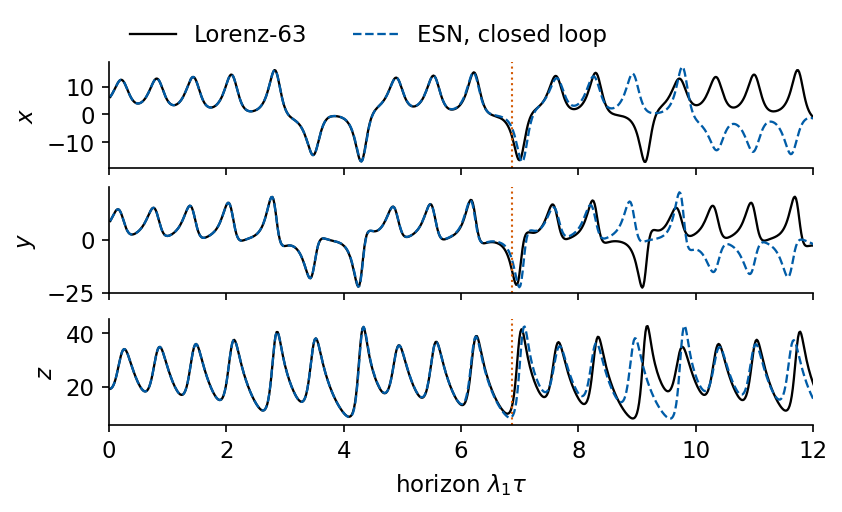

In [6]:
H_FC = 800                                                          # forecast length, 16 time units
K_ORIG = np.arange(N_TRAIN + 200, N_TRAIN + N_TEST - H_FC, 100)     # forecast origins in the test block
THR = 0.4                                                           # threshold of the normalised error

def forecast_errors(p, R, ks, H):
    # e(t) = |u_hat - u| / sqrt(<|u - <u>|^2>) for closed-loop forecasts started from the states R[k]
    P = np.asarray(jax.vmap(lambda r: free_run(r, p, H))(R[ks]))
    true = Un[ks[:, None] + 1 + np.arange(H)[None, :]]
    return P, np.linalg.norm(P - true, axis=-1) / D_NORM

def valid_times(E):
    # first time (in Lyapunov times) at which e(t) > THR; a forecast that stays below is set to the horizon
    exceed = E > THR
    j = np.where(exceed.any(1), np.argmax(exceed, 1) + 1, E.shape[1])
    return j * DT / T_LYAP, ~exceed.any(1)

P_fc, E_fc = forecast_errors(esn, R_all, K_ORIG, H_FC)
tv, censored = valid_times(E_fc)
t_fc = np.arange(1, H_FC + 1) * DT / T_LYAP                        # lead time in Lyapunov times
nums["weather"] = dict(n_orig=len(K_ORIG), H_in_T=H_FC * DT / T_LYAP, thr=THR, tv_median=float(np.median(tv)),
                       tv_mean=float(tv.mean()), tv_q10=float(np.quantile(tv, 0.1)), tv_q90=float(np.quantile(tv, 0.9)),
                       tv_min=float(tv.min()), tv_max=float(tv.max()), n_censored=int(censored.sum()))
print(f"{len(K_ORIG)} origins: valid time median {np.median(tv):.2f}, 10-90% {np.quantile(tv, 0.1):.2f}-{np.quantile(tv, 0.9):.2f},"
      f" range {tv.min():.2f}-{tv.max():.2f} Lyapunov times; {censored.sum()} never exceed {THR}")

i_ex = int(np.argsort(tv)[len(tv) // 2])                            # the origin with the median valid time
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(3, 1, figsize=(5.5, 3.3), sharex=True, layout="constrained")
    true = Un[K_ORIG[i_ex] + 1 + np.arange(H_FC)] * sd + mu
    pred = P_fc[i_ex] * sd + mu
    for j, (ax, lab) in enumerate(zip(axs, "xyz")):
        ax.plot(t_fc, true[:, j], color="k", lw=1.1, label="Lorenz-63")
        ax.plot(t_fc, pred[:, j], color=UJBlue, lw=1.1, ls="--", label="ESN, closed loop")
        ax.axvline(tv[i_ex], color=DSOrange, lw=1.0, ls=":")
        ax.set_ylabel(f"${lab}$")
    axs[0].legend(loc="lower left", ncol=2, bbox_to_anchor=(0, 0.95))
    axs[2].set_xlabel(r"horizon $\lambda_1\tau$"); axs[2].set_xlim(0, 12)
    save(fig, "fig_lab049_forecast"); plt.show()
nums["weather"]["tv_example"] = float(tv[i_ex])

The forecast follows all three coordinates through several turns around both fixed points and then departs from the truth. After the departure it continues as a plausible Lorenz trajectory that is out of phase with the truth, which is what an error of size $e\approx1$ looks like on the attractor.

The left panel below shows $e(\tau)$ for every sixth origin (thin lines), the geometric mean $\exp\langle\ln e(\tau)\rangle$ over all origins (dark line) and a line of slope $\lambda_1$ (dashed orange). The right panel shows the distribution of the valid times over the origins, with the median (dark line) and the predictability time computed below (dashed orange).

first-step error delta_0 = 1.9e-06; growth rate in [1.70, 6.58]: 0.93 lambda_1; extrapolated delta_eff = 2.1e-04
T = ln(Delta/delta_0)/lambda_1 = 12.28, with delta_eff 7.54; median valid time 6.87


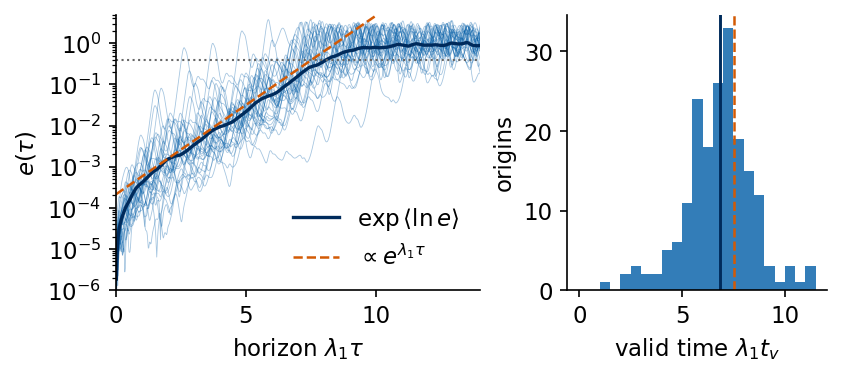

In [7]:
logE = np.log(E_fc)
mlog = logE.mean(0)                                                 # <ln e(t)> over the origins
delta0 = float(np.exp(mlog[0]))                                    # geometric mean of the first-step error
win = (mlog > np.log(1e-3)) & (mlog < np.log(1e-1))                # range of exponential growth
slope, icpt = np.polyfit(t_fc[win], mlog[win], 1)                  # ln e = icpt + slope * lambda_1 t
delta_eff = float(np.exp(icpt))
T_pred0 = np.log(THR / delta0)                                     # T = ln(Delta/delta_0)/lambda_1, in Lyapunov times
T_pred_eff = np.log(THR / delta_eff)
nums["growth"] = dict(delta0=delta0, slope=float(slope), delta_eff=delta_eff, T_pred0=float(T_pred0),
                      T_pred_eff=float(T_pred_eff), ratio=delta_eff / delta0, win_lo=float(t_fc[win].min()), win_hi=float(t_fc[win].max()))
print(f"first-step error delta_0 = {delta0:.1e}; growth rate in [{t_fc[win].min():.2f}, {t_fc[win].max():.2f}]:"
      f" {slope:.2f} lambda_1; extrapolated delta_eff = {delta_eff:.1e}")
print(f"T = ln(Delta/delta_0)/lambda_1 = {T_pred0:.2f}, with delta_eff {T_pred_eff:.2f}; median valid time {np.median(tv):.2f}")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained", width_ratios=(1.4, 1))
    ax = axs[0]
    for e in E_fc[::6]:
        ax.semilogy(t_fc, e, color=UJBlue, lw=0.4, alpha=0.35)
    ax.semilogy(t_fc, np.exp(mlog), color=UJNavy, lw=1.6, label=r"$\exp\langle\ln e\rangle$")
    tl = np.linspace(0, 10, 50)
    ax.semilogy(tl, delta_eff * np.exp(tl), color=DSOrange, ls="--", lw=1.2, label=r"$\propto e^{\lambda_1\tau}$")
    ax.axhline(THR, color="0.4", ls=":", lw=1.0)
    ax.set_ylim(1e-6, 5); ax.set_xlim(0, 14)
    ax.set_xlabel(r"horizon $\lambda_1\tau$"); ax.set_ylabel(r"$e(\tau)$"); ax.legend(loc="lower right")
    ax = axs[1]
    ax.hist(tv, bins=np.arange(0, tv.max() + 0.5, 0.5), color=UJBlue, alpha=0.8)
    ax.axvline(np.median(tv), color=UJNavy, lw=1.4)
    ax.axvline(T_pred_eff, color=DSOrange, ls="--", lw=1.2)
    ax.set_xlabel(r"valid time $\lambda_1 t_v$"); ax.set_ylabel("origins")
    save(fig, "fig_lab049_valid_time"); plt.show()

The valid time over the 190 origins has the median $\lambda_1t_v=6.9$, and 80% of the origins fall between 4.9 and 8.7 Lyapunov times. The full range from 1.0 to 11.2 shows that the predictability differs strongly between origins on the same attractor.

The mean logarithmic error grows in two stages. During the first fraction of a Lyapunov time it rises from the first-step value $\delta_0=1.9\times10^{-6}$ much faster than the slope $\lambda_1$ allows, and the later exponential stage extrapolates back to an initial error 114 times larger than $\delta_0$. We attribute this stage to the reservoir state relaxing away from the state it had when driven by the data, a growth of the model error that the Lorenz flow itself does not have. Afterwards the error grows exponentially at the rate 0.93$\,\lambda_1$, fitted between $\lambda_1\tau=1.7$ and 6.6. The predictability time with the first-step error, $\lambda_1T_p=\ln(\varepsilon/\delta_0)=12.3$ Lyapunov times, overestimates the median valid time by almost a factor of two. With the effective initial error $\delta_{\rm eff}=2.1\times10^{-4}$, the intercept of the exponential stage, it gives $\lambda_1T_p=\ln(\varepsilon/\delta_{\rm eff})=7.5$, close to the measured median of 6.9. The forecast horizon is therefore set by the chaos of the Lorenz flow once the initial model error is accounted for, and a tenfold smaller effective error would add only $\ln10\approx2.3$ Lyapunov times.

<hr/>
## 5. Long-term statistics

The same reservoir now runs freely for 110000 steps, about 1988 Lyapunov times, starting from its state at the end of the test block. The run takes 2.2 s. The largest normalised coordinate reached by the free run is 2.92, against 3.01 for the true long run, so the free run stays bounded. The figure shows the last 20000 steps of the true long run and of the free run in the $(x,z)$ plane.

free run of 110000 steps = 1988 Lyapunov times in 2.3 s; largest |u_hat| (normalised) 2.92, truth 3.01


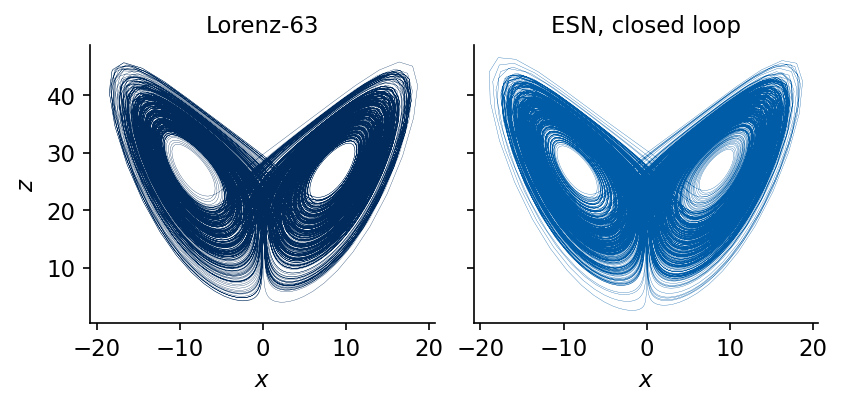

In [8]:
t0 = time.time()
P_long = np.asarray(free_run(R_all[-1], esn, N_LONG))              # free run from the last test state
t_free = time.time() - t0
assert np.isfinite(P_long).all()
P_long_p = P_long * sd + mu
nums["climate"] = dict(t_free=t_free, max_abs=float(np.abs(P_long).max()), max_abs_true=float(np.abs(Un_long).max()))
print(f"free run of {N_LONG} steps = {N_LONG * DT / T_LYAP:.0f} Lyapunov times in {t_free:.1f} s;"
      f" largest |u_hat| (normalised) {np.abs(P_long).max():.2f}, truth {np.abs(Un_long).max():.2f}")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.6), sharex=True, sharey=True, layout="constrained")
    for ax, Q, lab, col in ((axs[0], U_long_p, "Lorenz-63", UJNavy), (axs[1], P_long_p, "ESN, closed loop", UJBlue)):
        ax.plot(Q[-20000:, 0], Q[-20000:, 2], color=col, lw=0.15)
        ax.set_title(lab, fontsize=11); ax.set_xlabel("$x$")
    axs[0].set_ylabel("$z$")
    save(fig, "fig_lab049_attractor"); plt.show()

Both projections show the two wings around $C_\pm$, with the same outer boundary and the same holes around the fixed points.

### Invariant densities

A chaotic attractor carries an invariant probability density, and long-time averages of any observable are averages over this density. We compare the histograms of $x$, $y$ and $z$ of the free run with those of the true long run. Their distance is the Wasserstein-1 distance
$$W_1(p,q)=\int_{-\infty}^{\infty}\big|F_p(s)-F_q(s)\big|\,ds ,$$
with $F_p$ and $F_q$ the cumulative distribution functions, computed with `scipy.stats.wasserstein_distance` in the normalised coordinates, so it is measured in units of the standard deviation. The figure shows the densities of the true run (grey) and of the free run (blue line), with $W_1$ above each panel.

W1(x): ESN vs truth 0.0160, second true run vs truth 0.0151
W1(y): ESN vs truth 0.0149, second true run vs truth 0.0134
W1(z): ESN vs truth 0.0152, second true run vs truth 0.0027


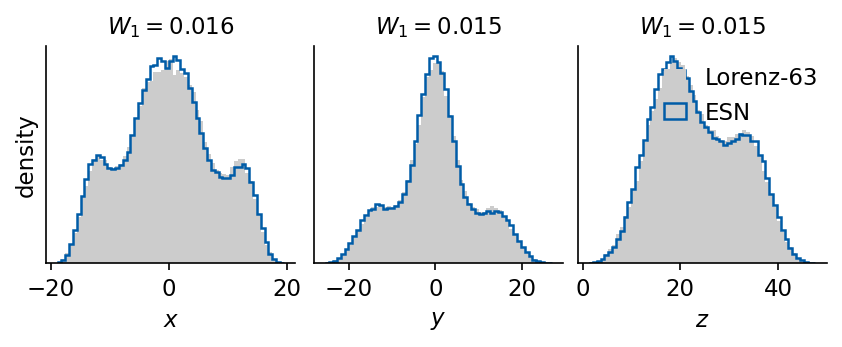

In [9]:
def w1_all(P, Q):
    # Wasserstein-1 distance of the one-dimensional marginal densities, in units of the training standard deviation
    return np.array([wasserstein_distance(P[:, j], Q[:, j]) for j in range(P.shape[1])])

w1_esn = w1_all(P_long, Un_long)
w1_ref = w1_all(Un_long2, Un_long)                                 # two independent true runs of the same length
nums["climate"].update(w1_esn=w1_esn.tolist(), w1_ref=w1_ref.tolist(), ratio=(w1_esn / w1_ref).tolist(),
                       w1_min=float(w1_esn.min()), w1_max=float(w1_esn.max()))
for j, lab in enumerate("xyz"):
    print(f"W1({lab}): ESN vs truth {w1_esn[j]:.4f}, second true run vs truth {w1_ref[j]:.4f}")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.2), layout="constrained")
    for j, (ax, lab) in enumerate(zip(axs, "xyz")):
        bins = np.linspace(U_long_p[:, j].min(), U_long_p[:, j].max(), 60)
        ax.hist(U_long_p[:, j], bins=bins, density=True, histtype="stepfilled", color="0.8", label="Lorenz-63")
        ax.hist(P_long_p[:, j], bins=bins, density=True, histtype="step", color=UJBlue, lw=1.2, label="ESN")
        ax.set_xlabel(f"${lab}$"); ax.set_yticks([])
        ax.set_title(rf"$W_1={w1_esn[j]:.3f}$", fontsize=11)
    axs[0].set_ylabel("density")
    axs[2].legend(loc="upper right", bbox_to_anchor=(1.05, 1.0), handlelength=1.0)
    save(fig, "fig_lab049_densities"); plt.show()

The densities agree within the resolution of the histograms, with $W_1=0.016$, 0.015 and 0.015 for $x$, $y$ and $z$. Two independent true runs of the same length differ by 0.015, 0.013 and 0.003. For $x$ and $y$ the free run is therefore as close to the truth as a second true run. For $z$ the difference is 6 times the difference between the true runs and still 0.015 standard deviations.

### Lorenz map

Lorenz reduced the dynamics to a one-dimensional map by recording the successive maxima $z_n$ of $z(t)$ and plotting $z_{n+1}$ against $z_n$ [Lorenz (1963)]. The points fall on a thin tent-shaped curve with slope of modulus above one, the mechanism of chaos in one dimension. The map tests the dynamics directly, since it relates consecutive events of one trajectory. The figure shows it for the true long run and the free run, with the diagonal (dotted). As a distance we use the root-mean-square difference of the bin-averaged $z_{n+1}$ in 30 bins of $z_n$ that contain at least five maxima in both runs.

maxima of z: truth 2936 in [29.58, 47.62], ESN 2925 in [30.58, 46.78]
RMS distance of the maps: ESN vs truth 0.063 (26 bins), second true run 0.041 (26 bins)


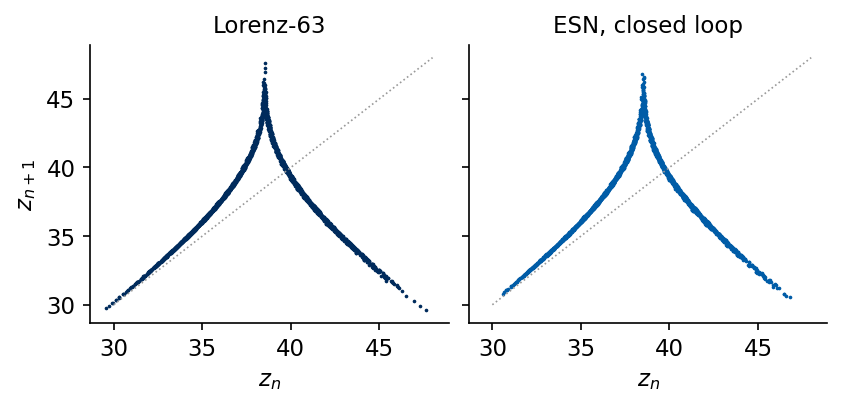

In [10]:
def z_maxima(z):
    i = np.nonzero((z[1:-1] > z[:-2]) & (z[1:-1] > z[2:]))[0] + 1
    return z[i]

def map_distance(ma, mb, bins):
    # RMS difference of the bin-averaged z_{n+1} as a function of z_n (bins with at least 5 maxima in both)
    def binned(m):
        idx = np.digitize(m[:-1], bins)
        return np.array([m[1:][idx == i].mean() if (idx == i).sum() >= 5 else np.nan for i in range(1, len(bins))])
    d = binned(ma) - binned(mb)
    return float(np.sqrt(np.nanmean(d ** 2))), int(np.isfinite(d).sum())

mz_true, mz_true2, mz_esn = z_maxima(U_long_p[:, 2]), z_maxima(U_long2_p[:, 2]), z_maxima(P_long_p[:, 2])
zbins = np.linspace(mz_true.min(), mz_true.max(), 31)
d_map_esn, nb_esn = map_distance(mz_esn, mz_true, zbins)
d_map_ref, nb_ref = map_distance(mz_true2, mz_true, zbins)
nums["lorenz_map"] = dict(n_max_true=len(mz_true), n_max_esn=len(mz_esn), d_esn=d_map_esn, d_ref=d_map_ref,
                          zmin=float(mz_true.min()), zmax=float(mz_true.max()),
                          zmin_esn=float(mz_esn.min()), zmax_esn=float(mz_esn.max()))
print(f"maxima of z: truth {len(mz_true)} in [{mz_true.min():.2f}, {mz_true.max():.2f}], ESN {len(mz_esn)}"
      f" in [{mz_esn.min():.2f}, {mz_esn.max():.2f}]")
print(f"RMS distance of the maps: ESN vs truth {d_map_esn:.3f} ({nb_esn} bins), second true run {d_map_ref:.3f} ({nb_ref} bins)")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.6), sharex=True, sharey=True, layout="constrained")
    for ax, m, lab, col in ((axs[0], mz_true, "Lorenz-63", UJNavy), (axs[1], mz_esn, "ESN, closed loop", UJBlue)):
        ax.plot(m[:-1], m[1:], ".", ms=1.5, color=col)
        ax.plot([30, 48], [30, 48], color="0.6", lw=0.8, ls=":")
        ax.set_title(lab, fontsize=11); ax.set_xlabel("$z_n$")
    axs[0].set_ylabel("$z_{n+1}$")
    save(fig, "fig_lab049_lorenz_map"); plt.show()

The free run reproduces the cusp and both branches. The true run has 2936 maxima between 29.6 and 47.6, and the free run 2925 between 30.6 and 46.8, so its map covers a slightly shorter interval. The distance between the maps is 0.06, against 0.04 between two true runs, in the units of $z$.

### Power spectrum

The power spectral density $S_x(f)$ of $x(t)$, estimated by Welch's method with segments of 8192 samples, measures how the variance is spread over frequencies. The figure compares the true run (black) and the free run (dashed blue) for $0<f\le4$, and the distance is the mean of $|\log_{10}S^{\rm ESN}_x-\log_{10}S^{\rm true}_x|$ over this band.

mean |log10 S_ESN - log10 S_true| = 0.101, second true run 0.100; peak frequency truth 0.018, ESN 0.067 (resolution 0.0061)


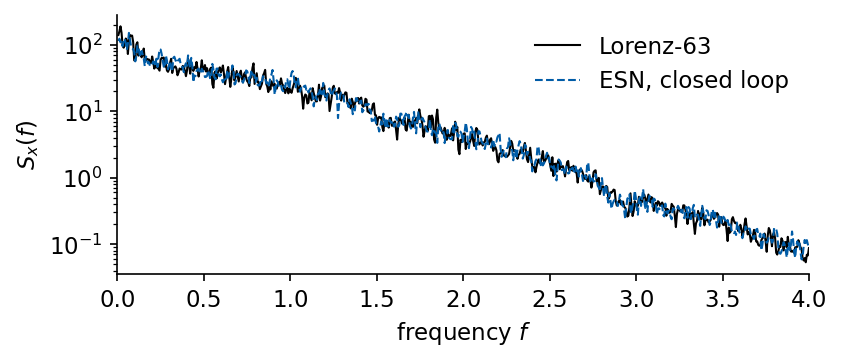

In [11]:
NPERSEG = 8192
f, S_true = welch(U_long_p[:, 0], fs=1 / DT, nperseg=NPERSEG)
_, S_true2 = welch(U_long2_p[:, 0], fs=1 / DT, nperseg=NPERSEG)
_, S_esn = welch(P_long_p[:, 0], fs=1 / DT, nperseg=NPERSEG)
band = (f > 0) & (f <= 4.0)
def log_spec_dist(Sa, Sb):
    # mean |log10 Sa - log10 Sb| over 0 < f <= 4
    return float(np.mean(np.abs(np.log10(Sa[band]) - np.log10(Sb[band]))))
f_peak = lambda S: float(f[band][np.argmax(S[band])])
nums["spectrum"] = dict(d_esn=log_spec_dist(S_esn, S_true), d_ref=log_spec_dist(S_true2, S_true),
                        f_peak_true=f_peak(S_true), f_peak_esn=f_peak(S_esn), df=float(f[1] - f[0]))
print(f"mean |log10 S_ESN - log10 S_true| = {nums['spectrum']['d_esn']:.3f}, second true run {nums['spectrum']['d_ref']:.3f};"
      f" peak frequency truth {f_peak(S_true):.3f}, ESN {f_peak(S_esn):.3f} (resolution {f[1] - f[0]:.4f})")

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.3), layout="constrained")
    ax.semilogy(f[band], S_true[band], color="k", lw=1.0, label="Lorenz-63")
    ax.semilogy(f[band], S_esn[band], color=UJBlue, lw=1.0, ls="--", label="ESN, closed loop")
    ax.set_xlabel("frequency $f$"); ax.set_ylabel("$S_x(f)$"); ax.set_xlim(0, 4)
    ax.legend(loc="upper right")
    save(fig, "fig_lab049_spectrum"); plt.show()

Both spectra are broad and decay with frequency without sharp peaks, as expected for a chaotic signal. The mean log distance is 0.101, equal to the distance 0.100 between two true runs, so the remaining difference is the estimation noise of the spectra.

### Lyapunov exponents of the reservoir

The closed-loop reservoir is a map $F$ on $\mathbb R^N$, and its Lyapunov exponents follow from the same Benettin method with the Jacobian
$$DF(\mathbf r_k)=(1-\alpha)\,\mathbb 1+\alpha\operatorname{diag}\big(1-\mathbf a_k^{2}\big)\,\big(W+W_{\rm in}W_{\rm out}^\top\big),\qquad \mathbf a_k=\tanh\big(W\mathbf r_k+W_{\rm in}(W_{\rm out}^\top\mathbf r_k+\mathbf b)+\boldsymbol\theta\big),$$
divided by $\Delta t$ to give rates per time unit. The product of $DF$ with the tangent vectors again comes from `jax.jvp`. We first check it against the full Jacobian from `jax.jacfwd` and against the formula above. The reservoir has $N=300$ exponents, and we compute the first four over 2000 time units.

In [12]:
def esn_step(r, p):
    return closed_step(r, p)

# check the Jacobian-vector product against the full Jacobian (jax.jacfwd) and the formula
# DF = (1 - alpha) I + alpha diag(1 - a^2)(W + W_in W_out^T), a = tanh(W r + W_in u_hat + theta)
r_chk = R_all[-1]
J_fwd = jax.jacfwd(lambda r: closed_step(r, esn))(r_chk)
a_chk = jnp.tanh(esn["W"] @ r_chk + esn["W_in"] @ (r_chk @ esn["W_out"] + esn["b"]) + esn["theta"])
J_formula = (1 - ALPHA) * jnp.eye(BASE["N"]) + ALPHA * (1 - a_chk ** 2)[:, None] * (esn["W"] + esn["W_in"] @ esn["W_out"].T)
q = jnp.asarray(np.random.default_rng(1).normal(size=BASE["N"]))
jvp_q = jax.jvp(lambda r: closed_step(r, esn), (r_chk,), (q,))[1]
d_jac = float(jnp.abs(J_fwd - J_formula).max()); d_jvp = float(jnp.abs(J_fwd @ q - jvp_q).max())
print(f"max |J_jacfwd - J_formula| = {d_jac:.1e}, max |J q - jvp| = {d_jvp:.1e}")

max |J_jacfwd - J_formula| = 1.1e-16, max |J q - jvp| = 1.2e-15


The Jacobian from `jax.jacfwd` agrees with the formula to $1.1\times10^{-16}$ and with the Jacobian-vector product to $1.2\times10^{-15}$. The figure compares the exponents of the reservoir (crosses) with those of the Lorenz flow (circles).

lambda_1: ESN +0.9094 +- 0.0041, Lorenz-63 +0.9036
lambda_2: ESN -0.0002 +- 0.0013, Lorenz-63 -0.0001
lambda_3: ESN -2.3979 +- 0.0176, Lorenz-63 -14.5701
lambda_4: ESN -7.0392 +- 0.0177, Lorenz-63 none
(9.9 s)


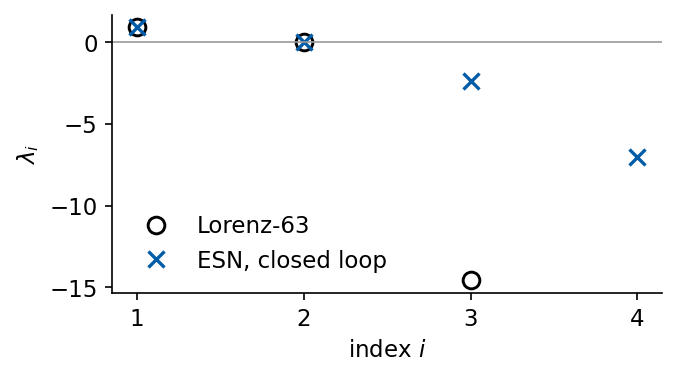

In [13]:

K_LE, N_LE_ESN = 4, 100000                                          # four exponents over 2000 time units
r_start = jnp.asarray(np.asarray(R_all[-1]))
r_start = jax.lax.fori_loop(0, 1000, lambda i, r: closed_step(r, esn), r_start)   # 20 time units of free run first
Q0 = jnp.asarray(np.linalg.qr(np.random.default_rng(0).normal(size=(BASE["N"], K_LE)))[0])
t0 = time.time()
logs_esn = np.asarray(benettin(esn_step, r_start, Q0, esn, N_LE_ESN))[N_LE_SKIP:]
lam_esn = logs_esn.mean(0) / DT
n_bl = len(logs_esn) // 10
lam_esn_err = logs_esn[:10 * n_bl].reshape(10, n_bl, K_LE).mean(1).std(0, ddof=1) / DT / np.sqrt(10)
t_le_esn = time.time() - t0
nums["lyap_esn"] = dict(lam=lam_esn.tolist(), err=lam_esn_err.tolist(), d_jac=d_jac, d_jvp=d_jvp, t=t_le_esn,
                        rel_err_lam1_pct=float(100 * abs(lam_esn[0] - lam1) / lam1))
for i in range(K_LE):
    ref = f"{lam_true[i]:+.4f}" if i < 3 else "none"
    print(f"lambda_{i+1}: ESN {lam_esn[i]:+.4f} +- {lam_esn_err[i]:.4f}, Lorenz-63 {ref}")
print(f"({t_le_esn:.1f} s)")

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.4), layout="constrained")
    ii = np.arange(1, K_LE + 1)
    ax.plot(ii[:3], lam_true, "o", ms=8, mfc="none", mec="k", mew=1.4, label="Lorenz-63")
    ax.plot(ii, lam_esn, "x", ms=8, color=UJBlue, mew=1.6, label="ESN, closed loop")
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_xticks(ii); ax.set_xlabel("index $i$"); ax.set_ylabel(r"$\lambda_i$")
    ax.legend(loc="lower left")
    save(fig, "fig_lab049_lyap_esn"); plt.show()

The largest exponent of the free run is $\lambda_1^{\rm ESN}=0.909\pm0.004$, against $\lambda_1=0.904\pm0.002$ for the Lorenz flow, a relative difference of 0.6%. The second exponent, $-0.0002\pm0.0013$, is zero within its error, as expected if the reservoir map imitates a time-sampled flow. The reservoir has learnt the expansion rate of the attractor from one-step data, and the computation needs only the trained model. The third exponent of the reservoir is $-2.40$, far from $\lambda_3=-14.57$, and the fourth, $-7.04$, has no counterpart in a three-dimensional flow. A plausible reason is that the training data lie on the attractor and carry no information on how fast states off the attractor are pulled back to it, so the reservoir supplies its own contraction rates in these directions. The climate statistics above depend on the motion on the attractor and come out right, while the strongly contracting direction of the Lorenz flow is out of reach of this model.

<hr/>
## 6. Reservoirs that fail

The reservoir above is one random draw at one setting. We now train 240 reservoirs, ten seeds for each of 24 settings with $N\in\{100,300\}$, $\rho\in\{0.5,0.9,1.2\}$, $\sigma_{\rm in}\in\{0.1,0.5\}$ and $\beta\in\{10^{-8},10^{-4}\}$, all on the same training data. Each one runs freely for 50000 steps, about 904 Lyapunov times, from its state at the end of the test block, and the free run is placed in one of five classes. It has diverged when a coordinate leaves $|u|<10$ or becomes undefined. It sits at a fixed point when every coordinate varies by less than $10^{-3}$ over the last 10000 steps. It is periodic when the maxima of $z$ in these steps, rounded to $0.01$, take fewer distinct values than 20% of their number. The remaining runs are aperiodic, and they are Lorenz-like when the largest of the three Wasserstein distances to the true densities is below 0.1, and aperiodic with a wrong climate otherwise. For reference, two true runs of this length differ by at most 0.031. For every run that does not diverge or stop we also compute $\lambda_1$ over 300 time units, continued from the end of the free run, and the median valid time over 43 origins. As a further control, the setting of the reservoir above is repeated without bias, $\boldsymbol\theta=0$.

In [14]:
def classify(P, Q, n_tail=10000):
    # class of a free run P against the true run Q (both normalised); the last column is used for the maxima test
    if not np.isfinite(P).all() or np.abs(P).max() > 10:
        return "diverged", np.nan
    tail = P[-n_tail:]
    w1 = float(w1_all(P, Q[:len(P)]).max())
    if tail.std(0).max() < 1e-3:
        return "fixed point", w1
    m = z_maxima(tail[:, -1])
    if len(np.unique(np.round(m, 2))) < 0.2 * len(m):
        return "periodic", w1
    return ("Lorenz-like" if w1 < 0.1 else "aperiodic, wrong climate"), w1

N_FREE = 50000                                    # free run of the scan, 1000 time units
w1_ref_scan = float(w1_all(Un_long2[:N_FREE], Un_long[:N_FREE]).max())
print(f"largest W1 between two true runs of {N_FREE} samples: {w1_ref_scan:.3f}; classification threshold 0.1")
print("classification of the free run of the reservoir above:", classify(P_long[:N_FREE], Un_long))
nums["scan_ref"] = dict(n_free=N_FREE, n_free_T=N_FREE * DT / T_LYAP, w1_ref=w1_ref_scan, w1_thr=0.1)

largest W1 between two true runs of 50000 samples: 0.031; classification threshold 0.1
classification of the free run of the reservoir above: ('Lorenz-like', 0.03542954002232498)


### Validation of the base setting

The setting of the reservoir studied above was fixed by a short trial whose record is not part of this notebook. We repeat the choice on the training block alone, so that neither the test block nor the long true runs enter it. For 18 settings with $N=300$ and seed 0, $\rho\in\{0.5,0.9,1.2\}$, $\sigma_{\rm in}\in\{0.1,0.5\}$ and $\beta\in\{10^{-8},10^{-6},10^{-4}\}$, the readout is fitted on the first 8000 training samples. Each setting is judged by the median valid time of 26 closed-loop forecasts of 600 steps started in the last 2000 training samples and by the class of a free run of 20000 steps, compared with the densities of the training block.

In [15]:
N_FIT_V = 8000                                                     # fit on samples 0..7999 of the training block
K_VAL = np.arange(N_FIT_V + 100, N_TRAIN - 600, 50)                # 26 validation origins, forecasts of 600 steps
def validate(rho, sigma_in, beta, seed=0, N=300):
    # readout fitted on k = 200..7999, forecasts and free run judged on the rest of the training block
    p = esn_draw(N, seed, rho, sigma_in, 0.1)
    R = esn_states(p, jnp.asarray(Un[:N_TRAIN]), jnp.zeros(N))
    k = np.arange(N_WASH, N_FIT_V)
    W_out, b = ridge_fit(R[k], jnp.asarray(Un[k + 1]), beta)
    p = dict(p, W_out=W_out, b=b)
    _, E = forecast_errors(p, R, K_VAL, 600)
    cls, w1 = classify(np.asarray(free_run(R[N_FIT_V - 1], p, 20000)), Un[:N_TRAIN])
    return dict(rho=rho, sigma_in=sigma_in, beta=beta, tv=float(np.median(valid_times(E)[0])), cls=cls, w1=w1)

t0 = time.time()
val = [validate(rho, si, beta) for rho in (0.5, 0.9, 1.2) for si in (0.1, 0.5) for beta in (1e-8, 1e-6, 1e-4)]
print(f"{len(K_VAL)} validation origins ({K_VAL[0]}..{K_VAL[-1]}); {time.time() - t0:.0f} s")
for d in val:
    print(f"rho = {d['rho']}, sigma_in = {d['sigma_in']}, beta = {d['beta']:.0e}: median valid time {d['tv']:.2f},"
          f" free run {d['cls']}, largest W1 {d['w1']:.3f}")
best_v = max(val, key=lambda d: d["tv"])
print(f"longest median valid time: rho = {best_v['rho']}, sigma_in = {best_v['sigma_in']}, beta = {best_v['beta']:.0e}")
nums["validation"] = dict(n_origins=len(K_VAL), rows=val)

26 validation origins (8100..9350); 29 s
rho = 0.5, sigma_in = 0.1, beta = 1e-08: median valid time 7.65, free run Lorenz-like, largest W1 0.043
rho = 0.5, sigma_in = 0.1, beta = 1e-06: median valid time 5.60, free run Lorenz-like, largest W1 0.026
rho = 0.5, sigma_in = 0.1, beta = 1e-04: median valid time 3.30, free run Lorenz-like, largest W1 0.037
rho = 0.5, sigma_in = 0.5, beta = 1e-08: median valid time 7.64, free run Lorenz-like, largest W1 0.047
rho = 0.5, sigma_in = 0.5, beta = 1e-06: median valid time 5.45, free run Lorenz-like, largest W1 0.051
rho = 0.5, sigma_in = 0.5, beta = 1e-04: median valid time 3.02, free run Lorenz-like, largest W1 0.008
rho = 0.9, sigma_in = 0.1, beta = 1e-08: median valid time 6.63, free run Lorenz-like, largest W1 0.034
rho = 0.9, sigma_in = 0.1, beta = 1e-06: median valid time 4.94, free run Lorenz-like, largest W1 0.028
rho = 0.9, sigma_in = 0.1, beta = 1e-04: median valid time 3.37, free run Lorenz-like, largest W1 0.057
rho = 0.9, sigma_in = 0

On these validation data the longest median valid times, 7.65 and 7.64 Lyapunov times, belong to $\rho=0.5$ with $\beta=10^{-8}$ and $\sigma_{\rm in}=0.1$ or $0.5$. The setting used above reaches 6.63 with a Lorenz-like free run, every setting with $\rho\le0.9$ and $\sigma_{\rm in}=0.1$ gives a Lorenz-like free run, and none of the six settings with $\rho=1.2$ does. The base setting is therefore a reasonable choice on data that exclude the test block and the long true runs, but it is not the best one by valid time on seed 0. We keep it, since the weather and climate results above refer to it, and the scan below compares $\rho=0.5$ and $0.9$ over ten seeds each.

In [16]:
K_SCAN = np.arange(N_TRAIN + 200, N_TRAIN + N_TEST - 600, 450)    # 43 origins, forecasts of 600 steps
def assess(N, seed, rho, sigma_in, sigma_theta, beta, lyap=True):
    p, R, e1 = train_esn(esn_draw(N, seed, rho, sigma_in, sigma_theta), Un, beta)
    _, E = forecast_errors(p, R, K_SCAN, 600)
    r_end, P = free_run_full(R[-1], p, N_FREE)
    P = np.asarray(P)
    cls, w1 = classify(P, Un_long)
    lam = np.nan
    if lyap and cls not in ("diverged", "fixed point"):
        # largest exponent over 300 time units, continued from the end of the free run
        q0 = jnp.asarray(np.linalg.qr(np.random.default_rng(seed).normal(size=(N, 1)))[0])
        lam = float(np.asarray(benettin(esn_step, r_end, q0, p, 15000))[500:].mean() / DT)
    return dict(N=N, seed=seed, rho=rho, sigma_in=sigma_in, sigma_theta=sigma_theta, beta=beta, nmse_one=e1,
                tv=float(np.median(valid_times(E)[0])), cls=cls, w1=w1, lam1=lam)

SEEDS = range(10)
GRID = [(N, rho, si, beta) for N in (100, 300) for rho in (0.5, 0.9, 1.2) for si in (0.1, 0.5) for beta in (1e-8, 1e-4)]
t0 = time.time()
scan = [assess(N, s, rho, si, 0.1, beta) for (N, rho, si, beta) in GRID for s in SEEDS]
t_scan = time.time() - t0
nobias = [assess(BASE["N"], s, BASE["rho"], BASE["sigma_in"], 0.0, BASE["beta"]) for s in SEEDS]
print(f"{len(scan)} + {len(nobias)} reservoirs trained and run in {time.time() - t0:.0f} s")
print(f"{'N':>4} {'rho':>4} {'s_in':>4} {'beta':>6} | " + " ".join(f"{c[:8]:>8}" for c in CLASSES) + " | median tv")
for (N, rho, si, beta) in GRID:
    rows = [d for d in scan if (d["N"], d["rho"], d["sigma_in"], d["beta"]) == (N, rho, si, beta)]
    cnt = Counter(d["cls"] for d in rows)
    print(f"{N:4d} {rho:4.1f} {si:4.1f} {beta:6.0e} | " + " ".join(f"{cnt[c]:8d}" for c in CLASSES)
          + f" | {np.median([d['tv'] for d in rows]):.2f}")
cnt_nb = Counter(d["cls"] for d in nobias)
print("no bias (sigma_theta = 0), baseline setting:", dict(cnt_nb))
tot = Counter(d["cls"] for d in scan)
good = [d for d in scan if d["cls"] == "Lorenz-like"]
base_rows = [d for d in scan if (d["N"], d["rho"], d["sigma_in"], d["beta"]) == (300, 0.9, 0.1, 1e-8)]
nums["scan"] = dict(n_runs=len(scan), n_settings=len(GRID), n_seeds=len(SEEDS), t_scan=t_scan,
                    totals={c: tot[c] for c in CLASSES}, nobias={c: cnt_nb[c] for c in CLASSES},
                    base={c: Counter(d["cls"] for d in base_rows)[c] for c in CLASSES},
                    lam1_good_median=float(np.median([d["lam1"] for d in good])),
                    lam1_good_q10=float(np.quantile([d["lam1"] for d in good], 0.1)),
                    lam1_good_q90=float(np.quantile([d["lam1"] for d in good], 0.9)),
                    tv_good_median=float(np.median([d["tv"] for d in good])),
                    lam1_good_min=float(min(d["lam1"] for d in good)), lam1_good_max=float(max(d["lam1"] for d in good)),
                    lam1_periodic_median=float(np.median([d["lam1"] for d in scan if d["cls"] == "periodic"])),
                    lam1_periodic_maxabs=float(max(abs(d["lam1"]) for d in scan if d["cls"] == "periodic")),
                    lam1_wrong_median=float(np.median([d["lam1"] for d in scan if d["cls"] == "aperiodic, wrong climate"])),
                    rows=[{k: v for k, v in d.items()} for d in scan])
for N in (100, 300):
    for rho in (0.5, 0.9, 1.2):
        rows = [d for d in scan if d["N"] == N and d["rho"] == rho]
        nums["scan"][f"good_N{N}_rho{rho}"] = sum(d["cls"] == "Lorenz-like" for d in rows)
for si in (0.1, 0.5):
    nums["scan"][f"good_sin{si}"] = sum(d["cls"] == "Lorenz-like" for d in scan if d["sigma_in"] == si)
for beta in (1e-8, 1e-4):
    nums["scan"][f"good_beta{beta:.0e}"] = sum(d["cls"] == "Lorenz-like" for d in scan if d["beta"] == beta)
print("totals:", dict(tot))
for rho in (0.5, 0.9, 1.2):
    e = [d["nmse_one"] for d in scan if d["rho"] == rho]
    nums["scan"][f"nmse_median_rho{rho}"] = float(np.median(e))
    nums["scan"][f"tv_median_rho{rho}"] = float(np.median([d["tv"] for d in scan if d["rho"] == rho]))
    print(f"rho = {rho}: median one-step NMSE {np.median(e):.1e}, median valid time {nums['scan'][f'tv_median_rho{rho}']:.2f}")
for beta in (1e-8, 1e-4):
    rows = [d for d in scan if d["beta"] == beta]
    sel = [d for d in rows if d["N"] == 300 and d["rho"] <= 0.9]
    nums["scan"][f"nmse_median_beta{beta:.0e}"] = float(np.median([d["nmse_one"] for d in rows]))
    nums["scan"][f"tv_median_beta{beta:.0e}_N300"] = float(np.median([d["tv"] for d in sel]))
    print(f"beta = {beta:.0e}: Lorenz-like {sum(d['cls'] == 'Lorenz-like' for d in rows)} of {len(rows)},"
          f" median one-step NMSE {nums['scan'][f'nmse_median_beta{beta:.0e}']:.1e},"
          f" median valid time for N = 300 and rho <= 0.9 {nums['scan'][f'tv_median_beta{beta:.0e}_N300']:.2f}")
print(f"ratio of the median one-step NMSE, beta = 1e-4 over 1e-8:"
      f" {nums['scan']['nmse_median_beta1e-04'] / nums['scan']['nmse_median_beta1e-08']:.0f}")
lam_per = np.array([d["lam1"] for d in scan if d["cls"] == "periodic"])
nums["scan"]["n_periodic_pos"] = int((lam_per > 0.1).sum()); nums["scan"]["n_periodic_neg"] = int((lam_per < -0.1).sum())
print(f"periodic runs with lambda_1 > 0.1: {(lam_per > 0.1).sum()}, < -0.1: {(lam_per < -0.1).sum()} of {len(lam_per)}")
nums["scan"]["tv_low_nmse"] = float(np.median([d["tv"] for d in scan if d["nmse_one"] < 1e-10]))
nums["scan"]["tv_high_nmse"] = float(np.median([d["tv"] for d in scan if d["nmse_one"] > 1e-5]))
print(f"median valid time for one-step NMSE < 1e-10: {nums['scan']['tv_low_nmse']:.2f}, > 1e-5: {nums['scan']['tv_high_nmse']:.2f}")
for c in ("periodic", "aperiodic, wrong climate"):
    l_ = [d["lam1"] for d in scan if d["cls"] == c]
    print(f"lambda_1 of the {c} runs: median {np.median(l_):.3f}, range {min(l_):.3f} to {max(l_):.3f}")
print(f"lambda_1 of the Lorenz-like runs: median {nums['scan']['lam1_good_median']:.3f},"
      f" 10-90% {nums['scan']['lam1_good_q10']:.3f}-{nums['scan']['lam1_good_q90']:.3f} (true {lam1:.3f})")

240 + 10 reservoirs trained and run in 381 s
   N  rho s_in   beta | Lorenz-l aperiodi periodic fixed po diverged | median tv
 100  0.5  0.1  1e-08 |        9        1        0        0        0 | 5.86
 100  0.5  0.1  1e-04 |        5        1        0        3        1 | 1.99
 100  0.5  0.5  1e-08 |        4        2        4        0        0 | 1.73
 100  0.5  0.5  1e-04 |        7        0        1        2        0 | 2.79
 100  0.9  0.1  1e-08 |        4        0        1        0        5 | 3.85
 100  0.9  0.1  1e-04 |        6        1        3        0        0 | 2.11
 100  0.9  0.5  1e-08 |        1        0        7        2        0 | 1.65
 100  0.9  0.5  1e-04 |        2        1        5        2        0 | 1.62
 100  1.2  0.1  1e-08 |        0        3        3        0        4 | 0.48
 100  1.2  0.1  1e-04 |        0        2        3        0        5 | 0.54
 100  1.2  0.5  1e-08 |        0        3        4        3        0 | 0.67
 100  1.2  0.5  1e-04 |        1      

Of the 240 free runs, 96 are Lorenz-like, 44 aperiodic with a wrong climate, 62 periodic, 22 end on a fixed point and 16 diverge. The figure counts the Lorenz-like runs out of ten for every setting.

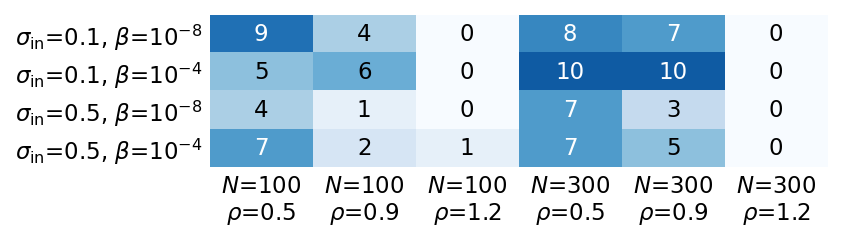

In [17]:
cols = [(N, rho) for N in (100, 300) for rho in (0.5, 0.9, 1.2)]
rws = [(si, beta) for si in (0.1, 0.5) for beta in (1e-8, 1e-4)]
M = np.array([[sum(d["cls"] == "Lorenz-like" for d in scan
                   if (d["N"], d["rho"], d["sigma_in"], d["beta"]) == (N, rho, si, beta)) for (N, rho) in cols]
              for (si, beta) in rws])
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 1.5), layout="constrained")      # printed size on the slide
    ax.imshow(M, cmap="Blues", vmin=0, vmax=12, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]}", ha="center", va="center", color="w" if M[i, j] > 6 else "k")
    ax.set_xticks(range(len(cols)), [rf"$N$={N}" + "\n" + rf"$\rho$={rho}" for (N, rho) in cols])
    ax.set_yticks(range(len(rws)), [rf"$\sigma_{{\rm in}}$={si}, $\beta$=$10^{{{int(np.log10(beta))}}}$" for (si, beta) in rws])
    ax.spines[:].set_visible(False); ax.tick_params(length=0)
    save(fig, "fig_lab049_success_map"); plt.show()

The spectral radius matters most. At $\rho=1.2$ only 1 of 80 runs is Lorenz-like, and the median one-step NMSE rises to $1.5\times10^{-5}$, against $6.0\times10^{-9}$ at $\rho=0.5$, with a median valid time of 0.7 Lyapunov times. At $\rho=0.5$ and $0.9$ the larger reservoir succeeds more often, 32 and 25 of 40 for $N=300$ against 25 and 13 for $N=100$. The weak input $\sigma_{\rm in}=0.1$ gives 59 Lorenz-like runs out of 120 and the strong input $\sigma_{\rm in}=0.5$ gives 37. The stronger ridge $\beta=10^{-4}$ gives 53 Lorenz-like runs against 43 for $10^{-8}$, but it raises the median one-step NMSE by a factor of 55, from $2.2\times10^{-9}$ to $1.2\times10^{-7}$, and lowers the median valid time of the runs with $N=300$ and $\rho\le0.9$ from 6.55 to 3.43 Lyapunov times. In this scan the smoother readout helps the climate and roughly halves the length of the forecasts. The setting of the reservoir above succeeds for 7 of its ten seeds. Without the bias the same ten reservoirs give 0 Lorenz-like runs, and 8 of them diverge. These counts hold for the Lorenz-63 data and the settings of this scan, with ten seeds per setting, so a single count carries an uncertainty of about one or two runs.

Where the free run is Lorenz-like, its largest exponent has the median 0.904 and lies between 0.621 and 0.930 over the 96 runs, against $\lambda_1=0.904$. The periodic runs have the median exponent $-2.6\times10^{-4}$, zero within the accuracy of a 300-time-unit estimate, and the aperiodic runs with a wrong climate have the median 1.00. The maxima test is a coarse criterion. Of the 62 runs it labels periodic, 3 have $\lambda_1>0.1$ and are aperiodic with maxima in a few narrow bands, and 5 have $\lambda_1<-0.1$ and are slowly decaying oscillations, so the class counts carry an uncertainty of a few runs. The left panel below places every run that did not diverge by its one-step NMSE and its largest Wasserstein distance, the right panel by its one-step NMSE and its median valid time, with the classification threshold dotted.

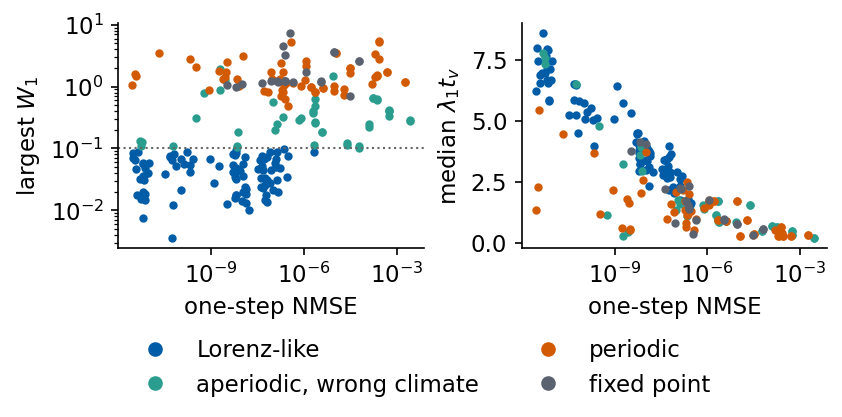

Lorenz-like                 96 runs, one-step NMSE 2.917e-12 - 2.15e-06
aperiodic, wrong climate    44 runs, one-step NMSE 4.883e-12 - 2.70e-03
periodic                    62 runs, one-step NMSE 2.857e-12 - 1.81e-03
fixed point                 22 runs, one-step NMSE 3.326e-09 - 6.13e-05
diverged                    16 runs, one-step NMSE 1.665e-11 - 2.60e-04


In [18]:

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.7), layout="constrained")
    for c in CLASSES[:-1]:
        rows = [d for d in scan if d["cls"] == c]
        axs[0].loglog([d["nmse_one"] for d in rows], [d["w1"] for d in rows], "o", ms=3, color=CCOL[c], label=c)
        axs[1].semilogx([d["nmse_one"] for d in rows], [d["tv"] for d in rows], "o", ms=3, color=CCOL[c])
    axs[0].axhline(0.1, color="0.4", ls=":", lw=1.0)
    axs[0].set_xlabel("one-step NMSE"); axs[0].set_ylabel(r"largest $W_1$")
    axs[1].set_xlabel("one-step NMSE"); axs[1].set_ylabel(r"median $\lambda_1 t_v$")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, markerscale=2)
    save(fig, "fig_lab049_onestep_vs_climate"); plt.show()

# one-step error ranges per class, for the text
nums["scan_classes"] = {}
for c in CLASSES:
    rows = [d for d in scan if d["cls"] == c]
    if rows:
        e = [d["nmse_one"] for d in rows]
        nums["scan_classes"][c] = dict(n=len(rows), nmse_min=float(min(e)), nmse_max=float(max(e)))
        print(f"{c:26s} {len(rows):3d} runs, one-step NMSE {min(e):.3e} - {max(e):.2e}")

A small one-step error is needed for a long forecast. The median valid time is 6.6 Lyapunov times for the runs with a one-step NMSE below $10^{-10}$ and 0.4 for those above $10^{-5}$, and every Lorenz-like run has a one-step NMSE of at most $2.15\times10^{-6}$. A small one-step error is not enough for a good climate. Periodic orbits, fixed points and wrong aperiodic attractors appear across the whole range of one-step errors, and the smallest one-step NMSE of the whole scan, $2.86\times10^{-12}$, belongs to a periodic run, essentially the same value as the smallest one of a Lorenz-like run, $2.92\times10^{-12}$. The open-loop fit only constrains the readout on the attractor, while the free run also depends on what $F$ does near it, where the training data say nothing.

The figure shows the two failures with the smallest one-step errors. The left panels show $x$ over the whole free run, the right panels the last 5000 steps in the $(x,z)$ plane on top of the true attractor (grey), with the last point marked.

   last point of the free run (-8.62, -8.65, 26.83); range of z over the last 5000 steps 26.8 to 26.8
   distance of the last point from the nearer of C+-: 0.27
fixed point: N = 300, seed 1, rho = 0.9, sigma_in = 0.5, beta = 1e-08, one-step NMSE 3.3e-09, median valid time 3.76, lambda_1 nan


   last point of the free run (-2.33, 15.28, 36.50); range of z over the last 5000 steps -6.4 to 56.4
   distance of the last point from the nearer of C+-: 15.92
periodic: N = 300, seed 7, rho = 0.5, sigma_in = 0.5, beta = 1e-08, one-step NMSE 2.9e-12, median valid time 1.36, lambda_1 -0.001


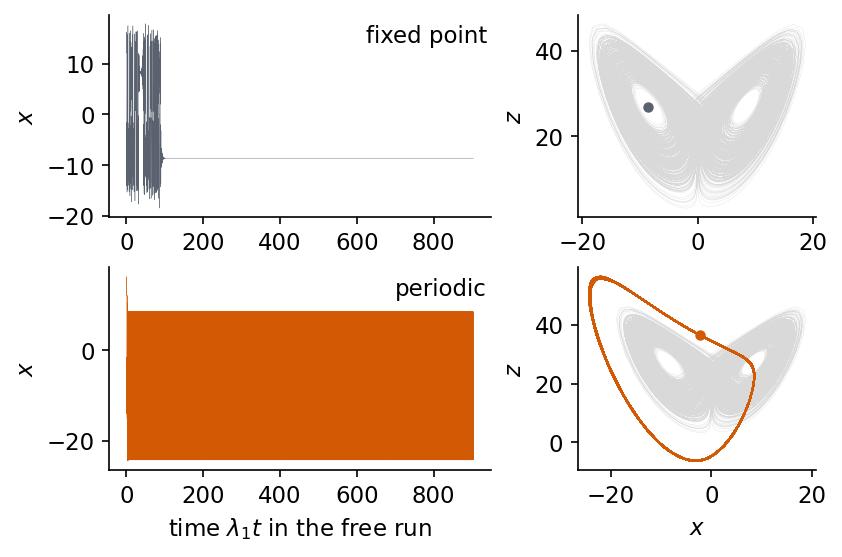

In [19]:
def best_of(c):
    # the run of class c with the smallest one-step error
    rows = [d for d in scan if d["cls"] == c]
    return min(rows, key=lambda d: d["nmse_one"]) if rows else None

fail = {c: best_of(c) for c in ("fixed point", "periodic")}
best_good = best_of("Lorenz-like")
traj_fail = {}
for c, d in fail.items():
    p, R, _ = train_esn(esn_draw(d["N"], d["seed"], d["rho"], d["sigma_in"], d["sigma_theta"]), Un, d["beta"])
    traj_fail[c] = np.asarray(free_run(R[-1], p, N_FREE)) * sd + mu
    nums[f"fail_{c.replace(' ', '_')}"] = {k: d[k] for k in ("N", "seed", "rho", "sigma_in", "beta", "nmse_one", "tv", "lam1")}
    nums[f"fail_{c.replace(' ', '_')}"]["end"] = traj_fail[c][-1].tolist()
    print(f"   last point of the free run ({traj_fail[c][-1, 0]:.2f}, {traj_fail[c][-1, 1]:.2f}, {traj_fail[c][-1, 2]:.2f});"
          f" range of z over the last 5000 steps {traj_fail[c][-5000:, 2].min():.1f} to {traj_fail[c][-5000:, 2].max():.1f}")
    nums[f"fail_{c.replace(' ', '_')}"]["zmax_tail"] = float(traj_fail[c][-5000:, 2].max())
    d_C = min(np.linalg.norm(traj_fail[c][-1] - np.array([sg * x_c, sg * x_c, R_L - 1])) for sg in (1, -1))
    nums[f"fail_{c.replace(' ', '_')}"]["dist_C"] = float(d_C)
    print(f"   distance of the last point from the nearer of C+-: {d_C:.2f}")
    print(f"{c}: N = {d['N']}, seed {d['seed']}, rho = {d['rho']}, sigma_in = {d['sigma_in']}, beta = {d['beta']:.0e},"
          f" one-step NMSE {d['nmse_one']:.1e}, median valid time {d['tv']:.2f}, lambda_1 {d['lam1']:.3f}")
nums["best_good_nmse"] = best_good["nmse_one"]

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 2, figsize=(5.5, 3.6), layout="constrained", width_ratios=(1.6, 1))
    tt = np.arange(1, N_FREE + 1) * DT / T_LYAP
    for i, c in enumerate(("fixed point", "periodic")):
        Q = traj_fail[c]
        axs[i, 0].plot(tt, Q[:, 0], color=CCOL[c], lw=0.2)
        axs[i, 0].set_ylabel("$x$")
        axs[i, 0].text(0.99, 0.95, c, transform=axs[i, 0].transAxes, ha="right", va="top")
        axs[i, 1].plot(U_long_p[:20000, 0], U_long_p[:20000, 2], color="0.85", lw=0.15)
        axs[i, 1].plot(Q[-5000:, 0], Q[-5000:, 2], color=CCOL[c], lw=0.8)
        axs[i, 1].plot(Q[-1, 0], Q[-1, 2], "o", color=CCOL[c], ms=4)
        axs[i, 1].set_ylabel("$z$")
    axs[1, 0].set_xlabel(r"time $\lambda_1 t$ in the free run"); axs[1, 1].set_xlabel("$x$")
    save(fig, "fig_lab049_failure"); plt.show()

The fixed-point case ($N=300$, seed 1, $\rho=0.9$, $\sigma_{\rm in}=0.5$, one-step NMSE $3.3\times10^{-9}$) first moves chaotically and then comes to rest at $(x,y,z)=(-8.62,-8.65,26.83)$, at a distance 0.27 from the nearer fixed point $C_\pm$ of the Lorenz equations. The reservoir has turned an unstable fixed point of the true flow into a stable one. The periodic case ($N=300$, seed 7, $\rho=0.5$, $\sigma_{\rm in}=0.5$, one-step NMSE $2.9\times10^{-12}$) leaves the attractor within a few Lyapunov times and settles on a large limit cycle that reaches $z=56$, outside the true attractor, with a median valid time of only 1.4 Lyapunov times.

<hr/>
## 7. Autoregression in closed loop

The same test applies to models without a reservoir. A linear autoregressive (AR) model and a nonlinear vector autoregression (NVAR) predict the increment from the last two states,
$$\mathbf u_{k+1}=\mathbf u_k+W_{\rm out}^\top\boldsymbol\phi(\mathbf u_k,\mathbf u_{k-1})+\mathbf b ,$$
where $\boldsymbol\phi$ is the six numbers of $(\mathbf u_k,\mathbf u_{k-1})$ for AR and these six numbers plus their 21 quadratic monomials for NVAR, the form used by Gauthier, Bollt, Griffith and Barbosa for the Lorenz system [Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)]. Both are fitted by ridge regression on the training block and closed in a loop like the reservoir, for three ridge strengths.

In [20]:
IU, JU = np.triu_indices(6)
def ar_feat(a, b, quad):
    # (u_k, u_{k-1}) and, for NVAR, all 21 quadratic monomials of these six numbers
    v = jnp.concatenate([a, b], -1)
    return jnp.concatenate([v, v[..., IU] * v[..., JU]], -1) if quad else v

@partial(jax.jit, static_argnums=(4, 5))
def ar_free(a, b, Wq, bq, quad, n):
    # closed loop u_{k+1} = u_k + W^T phi(u_k, u_{k-1}) + b
    def step(carry, _):
        a, b = carry
        n_ = a + ar_feat(a, b, quad) @ Wq + bq
        return (n_, a), n_
    return jax.lax.scan(step, (a, b), None, length=n)[1]

k = np.arange(1, N_TRAIN)
ar_res = {}
for quad in (False, True):
    for beta in (1e-8, 1e-6, 1e-4):
        Wq, bq = ridge_fit(ar_feat(jnp.asarray(Un[k]), jnp.asarray(Un[k - 1]), quad), jnp.asarray(Un[k + 1] - Un[k]), beta)
        F_te = ar_feat(jnp.asarray(Un[k_te]), jnp.asarray(Un[k_te - 1]), quad)
        e1 = float(np.mean(np.mean((np.asarray(Un[k_te] + F_te @ Wq + bq) - Un[k_te + 1]) ** 2, 0) / Un[k_te + 1].var(0)))
        P = np.asarray(ar_free(jnp.asarray(Un[-1]), jnp.asarray(Un[-2]), Wq, bq, quad, N_FREE))
        cls, w1 = classify(P, Un_long)
        bad = ~np.isfinite(P).all(1) | (np.abs(np.nan_to_num(P, nan=1e9)).max(1) > 10)
        t_div = float(np.argmax(bad) * DT / T_LYAP) if bad.any() else None
        name = ("NVAR" if quad else "AR") + f"_{beta:.0e}"
        ar_res[name] = dict(nmse_one=e1, cls=cls, w1=w1, t_div=t_div, P=P)
        if not quad:
            A1, A2 = np.asarray(Wq[:3]).T, np.asarray(Wq[3:]).T
            Mc = np.block([[np.eye(3) + A1, A2], [np.eye(3), np.zeros((3, 3))]])
            ar_res[name]["spec_rad"] = float(np.abs(np.linalg.eigvals(Mc)).max())
        print(f"{name:10s} one-step NMSE {e1:.1e}, free run: {cls}" + (f", W1 {w1:.3f}" if np.isfinite(w1) else "")
              + (f", leaves |u|<10 at lambda_1 t = {t_div:.1f}" if t_div is not None else "")
              + (f", spectral radius of the linear map {ar_res[name]['spec_rad']:.6f}" if not quad else ""))
nums["ar_nvar"] = {k_: {kk: v for kk, v in d.items() if kk != "P"} for k_, d in ar_res.items()}

AR_1e-08   one-step NMSE 4.0e-04, free run: fixed point, W1 0.832, spectral radius of the linear map 0.991202
AR_1e-06   one-step NMSE 4.0e-04, free run: fixed point, W1 0.832, spectral radius of the linear map 0.991202
AR_1e-04   one-step NMSE 4.0e-04, free run: fixed point, W1 0.832, spectral radius of the linear map 0.991198


NVAR_1e-08 one-step NMSE 1.7e-09, free run: diverged, leaves |u|<10 at lambda_1 t = 3.8
NVAR_1e-06 one-step NMSE 2.0e-09, free run: Lorenz-like, W1 0.025


NVAR_1e-04 one-step NMSE 8.2e-09, free run: Lorenz-like, W1 0.036


The AR model has the one-step NMSE $4.0\times10^{-4}$ and relaxes to a fixed point for every ridge strength. A closed-loop linear model is a linear map of $(\mathbf u_k,\mathbf u_{k-1})$, and its largest eigenvalue modulus, 0.9912, is below one, so every trajectory converges to its fixed point. A linear map can decay, grow or oscillate, and it has no bounded chaotic motion at all. NVAR reaches a one-step NMSE of $1.7\times10^{-9}$ at $\beta=10^{-8}$ and leaves the attractor after 3.8 Lyapunov times of free run, after which it runs away. At $\beta=10^{-6}$ and $10^{-4}$ the free run is Lorenz-like, with the largest Wasserstein distances 0.025 and 0.036. The figure shows the first 20000 steps of three of these free runs on top of the true attractor (grey), with the last plotted point marked.

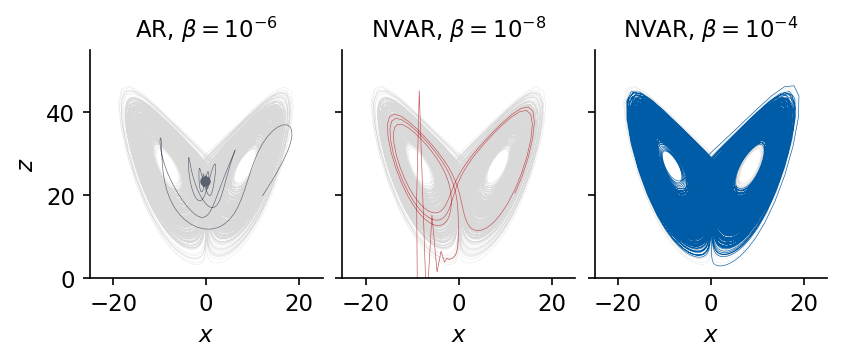

In [21]:

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.3), sharex=True, sharey=True, layout="constrained")
    for ax, name, lab in zip(axs, ("AR_1e-06", "NVAR_1e-08", "NVAR_1e-04"),
                             (r"AR, $\beta=10^{-6}$", r"NVAR, $\beta=10^{-8}$", r"NVAR, $\beta=10^{-4}$")):
        Q = ar_res[name]["P"] * sd + mu
        ok = np.isfinite(Q).all(1) & (np.abs(Q - mu).max(1) < 60)
        Q = Q[: np.argmin(ok) if not ok.all() else len(Q)]
        ax.plot(U_long_p[:20000, 0], U_long_p[:20000, 2], color="0.85", lw=0.15)
        ax.plot(Q[:20000, 0], Q[:20000, 2], color=CCOL[ar_res[name]["cls"]], lw=0.3)
        ax.plot(Q[min(len(Q), 20000) - 1, 0], Q[min(len(Q), 20000) - 1, 2], "o", color=CCOL[ar_res[name]["cls"]], ms=4)
        ax.set_title(lab, fontsize=11); ax.set_xlabel("$x$")
    axs[0].set_ylabel("$z$"); axs[0].set_xlim(-25, 25); axs[0].set_ylim(0, 55)
    save(fig, "fig_lab049_ar_nvar"); plt.show()

The quadratic features contain the quadratic nonlinearity of the Lorenz equations, and with a moderate ridge two delays are enough here. The free run of NVAR still depends on the ridge strength, as that of the reservoir does, and its smallest one-step error, at $\beta=10^{-8}$, again comes with the worst free run.

<hr/>
## 8. Forecasting from $x$ alone

In an experiment usually only one coordinate is measured. Takens' delay embedding replaces the missing coordinates by past values of the measured one [F. Takens, Lect. Notes Math. **898**, 366 (1981), [doi:10.1007/BFb0091924](https://doi.org/10.1007/BFb0091924)], and we feed the reservoir the delay vector $(x_k,x_{k-8},x_{k-16})$, with a delay of 8 samples or 0.16 time units, or only $x_k$ as a scalar input. The readout predicts $x_{k+1}$, and in the closed loop the prediction is appended to the record of past values from which the next delay vector is formed. We use $N=500$, $\rho=0.5$, $\sigma_{\rm in}=0.3$ and $\beta=10^{-6}$ and ten seeds for each input. This setting was fixed by a short trial on the first seed whose record is not part of this notebook, so it is not a validated choice, and the counts below hold for this setting only. The classification is the one of the scan, applied to $x$ alone, with the maxima of $x$ in place of those of $z$.

In [22]:
D_LAG, M_DEL = 8, 3                                                   # delay 8 samples = 0.16 time units
x_n = Un[:, 0]
def delay_input(x, m):
    # rows (x_k, x_{k-d}, ..., x_{k-(m-1)d}); the first (m-1)d rows repeat x_0 for the missing past
    return np.stack([np.r_[np.full(i * D_LAG, x[0]), x[:len(x) - i * D_LAG]] for i in range(m)], 1)

@partial(jax.jit, static_argnums=(2, 3))
def free_run_delay(r0, p, m, n, buf0):
    # closed loop with a delay input: the predicted x is appended to the buffer of past values
    def step(carry, _):
        r, buf = carry
        x_hat = r @ p["W_out"] + p["b"]                       # shape (1,)
        buf = jnp.concatenate([buf[1:], x_hat])
        u = buf[::-1][::D_LAG][:m]
        r = (1 - p["alpha"]) * r + p["alpha"] * jnp.tanh(p["W"] @ r + p["W_in"] @ u + p["theta"])
        return (r, buf), x_hat[0]
    return jax.lax.scan(step, (r0, buf0), None, length=n)[1]

XO = dict(N=500, rho=0.5, sigma_in=0.3, sigma_theta=0.1, beta=1e-6)
x_res = {}
for m in (1, M_DEL):
    Uin = delay_input(x_n, m)
    x_res[m] = []
    for s in SEEDS:
        p = esn_draw(XO["N"], s, XO["rho"], XO["sigma_in"], XO["sigma_theta"], dim=m)
        R = esn_states(p, jnp.asarray(Uin), jnp.zeros(XO["N"]))
        kk = np.arange(N_WASH, N_TRAIN)
        W_out, b = ridge_fit(R[kk], jnp.asarray(x_n[kk + 1, None]), XO["beta"])
        p = dict(p, W_out=W_out, b=b)
        e1 = float(np.mean((np.asarray(R[kk] @ W_out + b)[:, 0] - x_n[kk + 1]) ** 2) / x_n[kk + 1].var())
        buf0 = jnp.asarray(x_n[-((m - 1) * D_LAG + 1):])
        P = np.asarray(free_run_delay(R[-1], p, m, N_FREE, buf0))[:, None]
        cls, w1 = classify(P, Un_long[:, :1])
        x_res[m].append(dict(seed=s, cls=cls, w1=w1, nmse_one=e1, P=P[:, 0]))
    cnt = Counter(d["cls"] for d in x_res[m])
    print(f"x only, m = {m}: " + ", ".join(f"{c} {cnt[c]}" for c in CLASSES if cnt[c])
          + " | one-step NMSE " + f"{min(d['nmse_one'] for d in x_res[m]):.1e}-{max(d['nmse_one'] for d in x_res[m]):.1e}")
    print("   per seed: " + ", ".join(f"{d['seed']} {d['cls']} (W1 {d['w1']:.3f})" for d in x_res[m]))
    nums[f"xonly_m{m}"] = dict({c: cnt[c] for c in CLASSES}, nmse_min=min(d["nmse_one"] for d in x_res[m]),
                               nmse_max=max(d["nmse_one"] for d in x_res[m]),
                               w1=[d["w1"] for d in x_res[m]])
nums["xonly"] = dict(XO, d_lag=D_LAG, m=M_DEL)
w_good = [d["w1"] for d in x_res[M_DEL] if d["cls"] == "Lorenz-like"]
if w_good:
    nums["xonly"].update(w1_good_min=min(w_good), w1_good_max=max(w_good))

x only, m = 1: periodic 5, fixed point 3, diverged 2 | one-step NMSE 6.5e-10-1.5e-09
   per seed: 0 periodic (W1 0.224), 1 periodic (W1 2.515), 2 diverged (W1 nan), 3 diverged (W1 nan), 4 periodic (W1 4.235), 5 periodic (W1 3.115), 6 fixed point (W1 1.127), 7 fixed point (W1 1.138), 8 periodic (W1 2.632), 9 fixed point (W1 1.102)


x only, m = 3: Lorenz-like 1, aperiodic, wrong climate 7, periodic 1, fixed point 1 | one-step NMSE 1.5e-10-2.9e-10
   per seed: 0 aperiodic, wrong climate (W1 0.155), 1 periodic (W1 1.594), 2 aperiodic, wrong climate (W1 0.139), 3 Lorenz-like (W1 0.011), 4 aperiodic, wrong climate (W1 0.126), 5 aperiodic, wrong climate (W1 0.351), 6 aperiodic, wrong climate (W1 0.128), 7 fixed point (W1 1.171), 8 aperiodic, wrong climate (W1 0.878), 9 aperiodic, wrong climate (W1 0.102)


With the scalar input, none of the ten free runs is Lorenz-like. 5 are periodic, 3 end on a fixed point and 2 diverge, although the one-step NMSE is between $6.5\times10^{-10}$ and $1.5\times10^{-9}$. With the delay input only 1 of the ten runs is Lorenz-like, seed 3 with the Wasserstein distance $W_1=0.011$ of the $x$ density. Of the others 7 are aperiodic with a wrong climate, 1 periodic and 1 at a fixed point. Five of these nine runs have $W_1$ between 0.10 and 0.16, just above the threshold 0.1, so the count of Lorenz-like runs depends strongly on the threshold. The figure shows the delay plot $(x(t),x(t-0.32))$ for the true run and for the free run with the smallest distance (seed 3, $W_1=0.011$).

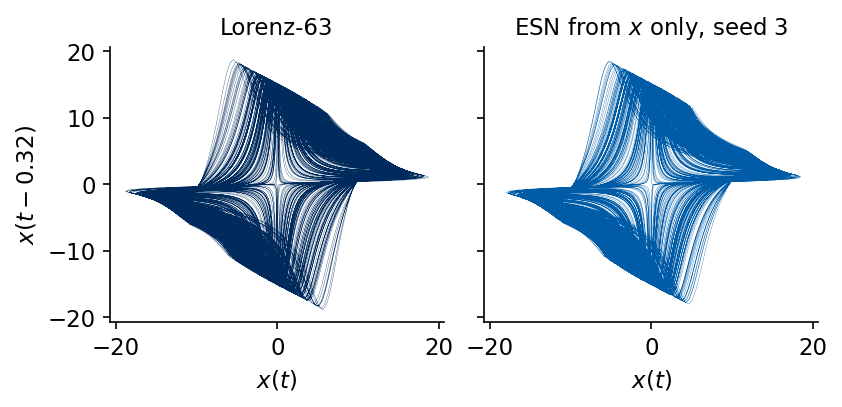

In [23]:
ex = min(x_res[M_DEL], key=lambda d: d["w1"] if np.isfinite(d["w1"]) else 1e9)
nums["xonly"]["example_seed"] = ex["seed"]; nums["xonly"]["example_w1"] = ex["w1"]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.6), sharex=True, sharey=True, layout="constrained")
    xt = U_long_p[:20000, 0]
    axs[0].plot(xt[2 * D_LAG:], xt[:-2 * D_LAG], color=UJNavy, lw=0.15); axs[0].set_title("Lorenz-63", fontsize=11)
    xe = ex["P"][-20000:] * sd[0] + mu[0]
    axs[1].plot(xe[2 * D_LAG:], xe[:-2 * D_LAG], color=CCOL[ex["cls"]], lw=0.15)
    axs[1].set_title(f"ESN from $x$ only, seed {ex['seed']}", fontsize=11)
    for ax in axs: ax.set_xlabel("$x(t)$")
    axs[0].set_ylabel(r"$x(t-0.32)$")
    save(fig, "fig_lab049_xonly"); plt.show()

The free run reproduces the shape of the delay plot. Measuring one coordinate makes the task harder than measuring all three, since the reservoir has to rebuild $y$ and $z$ from the past of $x$, and in our runs the success rate drops from 7 of ten for the full state, at $N=300$, $\rho=0.9$, $\sigma_{\rm in}=0.1$ and $\beta=10^{-8}$, to 1 of ten with a delay input and to zero with the scalar input, both at $N=500$, $\rho=0.5$, $\sigma_{\rm in}=0.3$ and $\beta=10^{-6}$. The settings differ, so the comparison mixes the effect of the input with that of the setting. The numbers for the input $x$ come from one unvalidated setting and leave open whether a better setting exists.

<hr/>
## Summary

An echo state network trained one step ahead on the Lorenz-63 state becomes an autonomous dynamical system once its prediction is fed back as the input. For the reservoir with $N=300$ units studied in detail, the short-term forecast, the weather of the model, stays below the error threshold 0.4 for a median of 6.9 Lyapunov times over 190 origins. The error grows at the rate 0.93$\,\lambda_1$ after a short initial stage, and the predictability time $T_p=\ln(\varepsilon/\delta_{\rm eff})/\lambda_1=7.5\,T_\lambda$ accounts for the measured valid time. The long free run, about 1988 Lyapunov times, reproduces the climate. The invariant densities differ from the truth by Wasserstein distances of 0.015 to 0.016 standard deviations, the Lorenz map and the power spectrum agree within the difference between two true runs or close to it, and the largest Lyapunov exponent of the reservoir map, 0.909, matches $\lambda_1=0.904$ of the Lorenz flow. The strongly negative exponent $\lambda_3=-14.57$ is not reproduced, most likely because the data on the attractor carry no information about the contraction towards it.

The success is a property of the random draw and of the setting. Of 240 reservoirs, 96 reproduce the Lorenz climate and the rest end on periodic orbits, on fixed points, on wrong aperiodic attractors or diverge. The spectral radius 1.2 fails almost always. A larger reservoir and a stronger ridge raise the number of runs with the right climate, while the stronger ridge also raises the median one-step error by a factor of 55 and roughly halves the median valid time. Without the bias of the units, tested at the base setting only, none of ten reservoirs reproduces the climate. A small one-step error is necessary for a long forecast and is not sufficient for a good climate, and the free run is the test that decides. Linear autoregression in closed loop relaxes to a fixed point for all three ridge strengths, quadratic autoregression reproduces the attractor for a moderate ridge and runs away for a weak one, and a reservoir that sees only $x$ recovers the attractor in one of ten runs with a delay input and in none with the scalar input. All results refer to the Lorenz-63 data, settings and random draws of this notebook.

## References

- E. N. Lorenz, *Deterministic nonperiodic flow*, J. Atmos. Sci. **20**, 130 (1963), [doi:10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2](https://doi.org/10.1175/1520-0469(1963)020%3C0130:DNF%3E2.0.CO;2)
- G. Benettin, L. Galgani, A. Giorgilli, J.-M. Strelcyn, *Lyapunov characteristic exponents for smooth dynamical systems and for Hamiltonian systems; a method for computing all of them. Part 1: Theory*, Meccanica **15**, 9 (1980), [doi:10.1007/BF02128236](https://doi.org/10.1007/BF02128236), and *Part 2: Numerical application*, Meccanica **15**, 21 (1980), [doi:10.1007/BF02128237](https://doi.org/10.1007/BF02128237)
- H. Jaeger, H. Haas, *Harnessing nonlinearity: predicting chaotic systems and saving energy in wireless communication*, Science **304**, 78 (2004), [doi:10.1126/science.1091277](https://doi.org/10.1126/science.1091277)
- J. Pathak, Z. Lu, B. R. Hunt, M. Girvan, E. Ott, *Using machine learning to replicate chaotic attractors and calculate Lyapunov exponents from data*, Chaos **27**, 121102 (2017), [doi:10.1063/1.5010300](https://doi.org/10.1063/1.5010300)
- Z. Lu, B. R. Hunt, E. Ott, *Attractor reconstruction by machine learning*, Chaos **28**, 061104 (2018), [doi:10.1063/1.5039508](https://doi.org/10.1063/1.5039508)
- F. Takens, *Detecting strange attractors in turbulence*, in Dynamical Systems and Turbulence, Warwick 1980, Lect. Notes Math. **898**, 366 (1981), [doi:10.1007/BFb0091924](https://doi.org/10.1007/BFb0091924)
- D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, *Next generation reservoir computing*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)

The last cell collects the numbers of this notebook in a JSON file and as LaTeX macros.

In [24]:
nums["runtime_s"] = round(time.time() - t_start, 1)
nums["runtime_min"] = nums["runtime_s"] / 60
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.ndarray): return to_py(o.tolist())
    if isinstance(o, float) and not np.isfinite(o): return None
    return o
with open(f"{OUT}/numbers_lab049.json", "w") as fh:
    json.dump(to_py(nums), fh, indent=1)

def sci(x, d=1):
    m, e = f"{x:.{d}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
L, W_, G = nums["lyap_true"], nums["weather"], nums["growth"]
macros = {
    "LambdaOne": f"{L['lam'][0]:.3f}", "LambdaTwo": f"{L['lam'][1]:.4f}", "LambdaThree": f"{L['lam'][2]:.2f}",
    "LambdaOneErr": f"{L['err'][0]:.3f}", "LambdaSum": f"{L['sum']:.3f}", "LyapTime": f"{L['T_lyap']:.2f}",
    "LyapSamples": f"{L['steps_per_T']:.0f}", "TrainLyap": f"{L['train_in_T']:.0f}", "LongLyap": f"{L['long_in_T']:.0f}",
    "EsnN": str(BASE["N"]), "OneStepTest": sci(nums["esn"]["nmse_one_test"]),
    "Threshold": f"{THR}", "NOrigins": str(W_["n_orig"]), "ValidMedian": f"{W_['tv_median']:.1f}",
    "ValidLow": f"{W_['tv_q10']:.1f}", "ValidHigh": f"{W_['tv_q90']:.1f}",
    "DeltaZero": sci(G["delta0"]), "DeltaEff": sci(G["delta_eff"]), "GrowthSlope": f"{G['slope']:.2f}",
    "TPredZero": f"{G['T_pred0']:.1f}", "TPredEff": f"{G['T_pred_eff']:.1f}",
    "WOneX": f"{nums['climate']['w1_esn'][0]:.3f}", "WOneY": f"{nums['climate']['w1_esn'][1]:.3f}",
    "WOneZ": f"{nums['climate']['w1_esn'][2]:.3f}", "WOneRefMax": f"{max(nums['climate']['w1_ref']):.3f}",
    "MapDistEsn": f"{nums['lorenz_map']['d_esn']:.2f}", "MapDistRef": f"{nums['lorenz_map']['d_ref']:.2f}",
    "SpecDistEsn": f"{nums['spectrum']['d_esn']:.3f}", "SpecDistRef": f"{nums['spectrum']['d_ref']:.3f}",
    "EsnLambdaOne": f"{nums['lyap_esn']['lam'][0]:.3f}", "EsnLambdaTwo": f"{nums['lyap_esn']['lam'][1]:.4f}",
    "EsnLambdaThree": f"{nums['lyap_esn']['lam'][2]:.2f}", "EsnLambdaFour": f"{nums['lyap_esn']['lam'][3]:.2f}",
    "EsnLambdaOneErr": f"{nums['lyap_esn']['err'][0]:.3f}",
    "ScanRuns": str(nums["scan"]["n_runs"]), "ScanGood": str(nums["scan"]["totals"]["Lorenz-like"]),
    "ScanFixed": str(nums["scan"]["totals"]["fixed point"]), "ScanPeriodic": str(nums["scan"]["totals"]["periodic"]),
    "ScanDiverged": str(nums["scan"]["totals"]["diverged"]),
    "ScanWrong": str(nums["scan"]["totals"]["aperiodic, wrong climate"]),
    "BaseGood": str(nums["scan"]["base"]["Lorenz-like"]), "NoBiasGood": str(nums["scan"]["nobias"]["Lorenz-like"]),
    "GoodLambdaMedian": f"{nums['scan']['lam1_good_median']:.3f}",
    "XonlyGoodOne": str(nums["xonly_m1"]["Lorenz-like"]), "XonlyGoodDelay": str(nums[f"xonly_m{M_DEL}"]["Lorenz-like"]),
    "Runtime": f"{nums['runtime_s'] / 60:.1f}",
}
bad = [k for k in macros if not k.isalpha()]
assert not bad, bad
with open(f"{OUT}/nb_numbers_lab049.tex", "w") as fh:
    for k, val in macros.items():
        fh.write(f"\\newcommand{{\\labfortynine{k}}}{{{val}}}\n")
print(f"{len(macros)} macros written; total runtime {nums['runtime_s'] / 60:.1f} min")

46 macros written; total runtime 9.7 min
